# Deteksi *Phishing* URL Umum dan Eksplorasi Klaster Tematik Rekrutmen
### LightGBM/XGBoost + Optuna + SHAP (Tahap 1, konfirmatori) → Transformer *Encoder-Autoencoder* tanpa label (Tahap 2, eksploratif)
**Notebook eksperimen — revisi pasca-masukan dosen (IFLP-ICDSOS 2026)**

---

## 1. Latar belakang dan perubahan desain

Dosen menilai dataset lama terlalu kecil. Dataset diganti dengan korpus URL *phishing* dan *legitimate* umum yang jauh lebih besar. Karena data baru **tidak memiliki label "job phishing"**, desain penelitian dipisah menjadi dua tahap dengan status klaim yang berbeda:

| | Tahap 1 (konfirmatori) | Tahap 2 (eksploratif) |
|---|---|---|
| Pertanyaan | Apakah URL *phishing* dapat dibedakan dari *legitimate*? | Apakah di antara URL *phishing* ada struktur laten bertema rekrutmen? |
| Data | 79.998 URL train, 38.387 URL test (fitur 24 kolom + teks URL) | Hanya URL berlabel *phishing* di train (dan URL test yang diprediksi *phishing*) |
| Model | LightGBM dan XGBoost + Optuna, `StratifiedGroupKFold` berbasis domain | Transformer *encoder-autoencoder* tanpa label + K-Means |
| Klaim yang sah | Metrik terukur dengan CV, uji pada *hold-out*, SHAP | Pembangkitan hipotesis; **bukan** "akurasi deteksi job phishing" |

**Keputusan data:** 7.873 URL *job phishing* dari dataset lama **tidak dipakai**, karena sebagian dibangkitkan oleh model terlatih sehingga tidak independen secara ilmiah. Akibatnya Tahap 2 tidak memiliki label *ground truth*; validasinya bergantung pada sampel audit berlabel manual (Tahap 7).

## 2. Arsitektur *pipeline*

```text
train (79.998)                          test (38.387)
      │                                       │
      ▼                                       ▼
┌───────────────────────────────────────────────────────────────┐
│ TAHAP 0  Audit & pembersihan                                  │
│  • samakan kolom 'URL'; normalisasi (skema/www/'/' akhir)     │
│  • buang duplikat & konflik label; group = registered domain  │
│  • buang dari train URL yang beririsan dengan test            │
└──────────────────────────────┬────────────────────────────────┘
                               ▼
┌───────────────────────────────────────────────────────────────┐
│ TAHAP 1  Seleksi fitur (zero-variance + redundansi has_http)  │
└──────────────────────────────┬────────────────────────────────┘
                               ▼
┌───────────────────────────────────────────────────────────────┐
│ TAHAP 2  Klasifikasi Phishing vs Legitimate                   │
│  • StratifiedGroupKFold 5-fold (grup = registered domain)     │
│  • Optuna (LightGBM, XGBoost); pilih model dari mean CV F1    │
│  • ambang dari prediksi out-of-fold                           │
│  • test: seluruh test, subset "domain belum pernah dilihat",  │
│    PR-AUC, ablasi tanpa fitur path                            │
└──────────────────────────────┬────────────────────────────────┘
                               ▼
┌───────────────────────────────────────────────────────────────┐
│ TAHAP 3  XAI Tahap 1: Gain, Permutation, SHAP + audit shortcut│
└──────────────────────────────┬────────────────────────────────┘
                               ▼
┌───────────────────────────────────────────────────────────────┐
│ TAHAP 4  Korpus Tahap 2 + uji ujung-ke-ujung                  │
│  • latih: URL phishing asli di train                          │
│  • uji: URL test yang diprediksi phishing (error propagation) │
│  • jangkar: kata kunci rekrutmen (tanpa data eksternal)       │
└──────────────────────────────┬────────────────────────────────┘
                               ▼
┌───────────────────────────────────────────────────────────────┐
│ TAHAP 5  Tokenisasi URL (BPE + placeholder ID acak/hex/angka) │
└──────────────────────────────┬────────────────────────────────┘
                               ▼
┌───────────────────────────────────────────────────────────────┐
│ TAHAP 6  Transformer Encoder-Autoencoder (tanpa label)        │
│  • masked-token reconstruction + cabang 23 fitur → latent z   │
│  • K-Means di ruang laten; k dipilih dari stabilitas          │
└──────────────────────────────┬────────────────────────────────┘
                               ▼
┌───────────────────────────────────────────────────────────────┐
│ TAHAP 7  Validasi klaster                                     │
│  • sampel audit untuk 2 anotator → kappa, purity, P/R + CI    │
│  • silhouette, DBI, stabilitas antar-seed (ARI)               │
│  • pembanding: TF-IDF char n-gram + K-Means                   │
│  • ablasi: token saja / fitur saja / gabungan                 │
└──────────────────────────────┬────────────────────────────────┘
                               ▼
┌───────────────────────────────────────────────────────────────┐
│ TAHAP 8  XAI Tahap 2: attention rollout + token occlusion,    │
│          profil centroid fitur                                │
└───────────────────────────────────────────────────────────────┘
```

## 3. Protokol evaluasi (ditetapkan sebelum eksperimen)

1. **Model Tahap 1 dipilih hanya dari rata-rata F1 pada `StratifiedGroupKFold` di train.** Test tidak dipakai untuk memilih model, hiperparameter, fitur, maupun ambang.
2. **Ambang klasifikasi** dipilih dari prediksi *out-of-fold* (OOF), karena train seimbang (50:50) sedangkan test memiliki proporsi *phishing* berbeda (sekitar 61,8%).
3. **Tahap 2 bersifat eksploratif.** Kata kunci rekrutmen hanya dipakai sebagai jangkar deskriptif. Klaim validitas klaster hanya boleh bersandar pada label manual independen (Tahap 7).
4. Semua hasil (tabel, gambar, model) disimpan ke Google Drive. Jika sesi terputus, jalankan ulang sel: Optuna, model, dan embedding yang sudah selesai dimuat dari *checkpoint*.

> **Panduan komputasi (A100 High-RAM, satu kali *run*):** estimasi total sekitar 25–40 menit. Batas waktu Optuna dan jumlah epoch diatur di sel konfigurasi (`CFG`). Jangan menjalankan mode `SMOKE_TEST = True` untuk hasil paper.

In [ ]:
# ===================== SETUP, KONFIGURASI, DAN PERANGKAT =====================
import os, sys, re, json, time, math, random, glob, warnings, subprocess, importlib, importlib.util
warnings.filterwarnings('ignore')
T0 = time.time()
def elapsed_min(): return (time.time() - T0) / 60

_missing = [p for p in ['optuna', 'shap', 'tokenizers', 'tldextract', 'lightgbm', 'xgboost'] if importlib.util.find_spec(p) is None]
if _missing:
    print('Memasang paket:', _missing)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q'] + _missing, check=False)
    importlib.invalidate_caches()

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
    from google.colab import drive
    drive.mount('/content/drive')
except Exception:
    IN_COLAB = False

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib
import torch, torch.nn as nn, torch.nn.functional as F
import lightgbm as lgb, xgboost as xgb, optuna, shap
from sklearn.base import clone
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.inspection import permutation_importance
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, precision_recall_curve,
                             silhouette_score, davies_bouldin_score, adjusted_rand_score,
                             normalized_mutual_info_score, cohen_kappa_score)
from scipy.stats import ttest_rel, wilcoxon, hypergeom
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 200)

# ---------------------------------------------------------------------
SMOKE_TEST = False   # True = uji cepat dengan data kecil. JANGAN dipakai untuk hasil paper.
# ---------------------------------------------------------------------
CFG = dict(
    SEED=42, N_SPLITS=5,
    OPTUNA_TRIALS=60, OPTUNA_TIMEOUT_S=420,          # batas per algoritma (trial ATAU detik, mana yang lebih dulu)
    PERM_SAMPLE=15000, PERM_REPEATS=5, SHAP_SAMPLE=6000, N_BOOT=500,
    MAX_LEN=64, VOCAB=6000, D_MODEL=128, N_HEAD=4, N_LAYER=3, D_FF=256, Z_DIM=16, DROPOUT=0.1,
    EPOCHS=25, BATCH=512, LR=1e-3, MASK_P=0.15, LAMBDA_BOW=1.0, LAMBDA_FEAT=1.0,
    SEEDS=[0, 1, 2], K_RANGE=list(range(2, 9)), SIL_SAMPLE=8000,
    AUDIT_N=450, OCC_URLS=250, SOFT_LIMIT_MIN=55,    # setelah SOFT_LIMIT_MIN menit, analisis opsional dilewati
)
if SMOKE_TEST:
    CFG.update(OPTUNA_TRIALS=3, OPTUNA_TIMEOUT_S=60, PERM_SAMPLE=1500, PERM_REPEATS=2, SHAP_SAMPLE=300, N_BOOT=30,
               VOCAB=1500, EPOCHS=1, SEEDS=[0, 1], K_RANGE=[2, 3, 4], SIL_SAMPLE=1500, AUDIT_N=60, OCC_URLS=20)
globals().update({k: v for k, v in CFG.items() if k.isupper()})

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
N_JOBS = os.cpu_count() or 2
if DEVICE == 'cuda':
    torch.backends.cuda.matmul.allow_tf32 = True; torch.backends.cudnn.allow_tf32 = True
XGB_DEVICE = 'cpu'
if DEVICE == 'cuda':
    try:
        xgb.XGBClassifier(n_estimators=2, device='cuda', tree_method='hist').fit(np.random.rand(60, 3), np.r_[np.zeros(30), np.ones(30)])
        XGB_DEVICE = 'cuda'
    except Exception as e:
        print('XGBoost GPU tidak tersedia, pakai CPU:', repr(e)[:120])

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed(SEED)

DATA_DIR = '/content/drive/MyDrive/ICDSOS' if IN_COLAB else os.getcwd()
OUT_DIR = os.path.join(DATA_DIR if IN_COLAB else '/home/claude', 'hasil_pipeline_v2' + ('_smoke' if SMOKE_TEST else ''))
os.makedirs(OUT_DIR, exist_ok=True)

def find_file(kind):
    dirs = [DATA_DIR, '/content', '/content/drive/MyDrive', '/mnt/user-data/uploads', os.getcwd()]
    for d in dirs:
        if not os.path.isdir(d): continue
        for p in sorted(glob.glob(os.path.join(d, '*features_24_hybrid*.csv'))):
            is_test = os.path.basename(p).lower().startswith('testing')
            if (kind == 'test') == is_test: return p
    return None

TRAIN_PATH, TEST_PATH = find_file('train'), find_file('test')
if (TRAIN_PATH is None or TEST_PATH is None) and IN_COLAB:
    from google.colab import files
    print('CSV tidak ditemukan di Drive. Unggah features_24_hybrid*.csv dan testing_features_24_hybrid*.csv.')
    files.upload(); TRAIN_PATH, TEST_PATH = find_file('train'), find_file('test')
if TRAIN_PATH is None or TEST_PATH is None:
    raise FileNotFoundError(f'CSV tidak ditemukan. Letakkan features_24_hybrid*.csv dan testing_features_24_hybrid*.csv di {DATA_DIR!r}.')

print(f'Perangkat: {DEVICE} | XGBoost: {XGB_DEVICE} | CPU: {N_JOBS} | torch {torch.__version__} | lightgbm {lgb.__version__} | xgboost {xgb.__version__}')
print('Train:', TRAIN_PATH); print('Test :', TEST_PATH); print('Output:', OUT_DIR)
if SMOKE_TEST: print('\n*** MODE SMOKE_TEST AKTIF: hasil BUKAN untuk paper ***')

Memasang paket: ['optuna', 'tldextract']
Mounted at /content/drive
Perangkat: cuda | XGBoost: cuda | CPU: 8 | torch 2.11.0+cu130 | lightgbm 4.6.0 | xgboost 3.4.1
Train: /content/drive/MyDrive/ICDSOS/features_24_hybrid.csv
Test : /content/drive/MyDrive/ICDSOS/testing_features_24_hybrid.csv
Output: /content/drive/MyDrive/ICDSOS/hasil_pipeline_v2


---
# TAHAP 0: Audit dan Pembersihan Data

Audit dilakukan **sebelum** pemodelan karena dua hal yang tidak terlihat pada dataset lama kini berpengaruh langsung pada validitas evaluasi:

1. **Duplikat tersembunyi.** URL yang tidak identik secara string tetapi sama setelah normalisasi (skema `http/https`, awalan `www.`, garis miring akhir, huruf besar/kecil) dianggap satu URL:
$$\text{norm}(u)=\text{lower}\big(\text{strip\_scheme}(u)\big)\ \to\ \text{buang } \texttt{www.}\ \to\ \text{buang } \texttt{/}\text{ akhir}$$
2. **Kebocoran tingkat domain.** URL *phishing* sering datang dari platform yang sama (pembuat situs, pemendek tautan, penyimpanan objek). Jika URL dari domain yang sama jatuh di train **dan** test, skor test mencerminkan kemampuan "mengenali platform", bukan kemampuan menggeneralisasi. Karena itu setiap URL diberi **grup = *registered domain*** (misalnya `weebly.com`) yang dipakai pada pembagian fold dan pada analisis subset test.

**Perlakuan:** (a) duplikat dan URL berlabel konflik dibuang dari masing-masing *split*; (b) URL di train yang (setelah normalisasi) juga ada di test dibuang dari **train**, sehingga test tidak diubah oleh isi train; (c) irisan domain train-test **dilaporkan**, bukan dibuang, dan dievaluasi lewat subset "domain belum pernah dilihat" pada Tahap 2.

In [ ]:
import tldextract
_ext = tldextract.TLDExtract(suffix_list_urls=(), cache_dir=None)   # daftar sufiks bawaan paket (tanpa unduh)
SCHEME_RE = re.compile(r'^[a-z][a-z0-9+.\-]*://')

def norm_url(u):
    s = SCHEME_RE.sub('', str(u).strip().lower())
    s = re.sub(r'^www\d*\.', '', s)
    return s.rstrip('/')

def reg_domain(u):
    s = SCHEME_RE.sub('', str(u).strip().lower())
    host = re.split(r'[/?#]', s, maxsplit=1)[0].split('@')[-1]
    host = re.sub(r':\d+$', '', host)
    e = _ext(host)
    try: dom = e.top_domain_under_public_suffix
    except AttributeError: dom = e.registered_domain
    return dom or host

def load_csv(path):
    d = pd.read_csv(path)
    d.columns = ['URL' if c.lower() == 'url' else c for c in d.columns]
    assert {'URL', 'ClassLabel'} <= set(d.columns), f'Kolom wajib hilang di {path}'
    assert d['ClassLabel'].isin([0, 1]).all() and d.isna().sum().sum() == 0, 'Label harus biner dan tanpa missing value'
    return d

raw_train, raw_test = load_csv(TRAIN_PATH), load_csv(TEST_PATH)

def clean_split(df):
    df = df.copy(); df['norm'] = df['URL'].map(norm_url)
    n_raw = len(df)
    n_lab = df.groupby('norm')['ClassLabel'].nunique()
    conflict = set(n_lab[n_lab > 1].index)
    df = df[~df['norm'].isin(conflict)]; n_conf = n_raw - len(df)
    n_before = len(df); df = df.drop_duplicates('norm', keep='first'); n_dup = n_before - len(df)
    return df.reset_index(drop=True), dict(raw=n_raw, konflik=n_conf, duplikat=n_dup)

train_df, st_tr = clean_split(raw_train); test_df, st_te = clean_split(raw_test)
overlap = set(train_df['norm']) & set(test_df['norm'])
n_train_before_overlap = len(train_df)
train_df = train_df[~train_df['norm'].isin(overlap)].reset_index(drop=True)
n_overlap_removed = n_train_before_overlap - len(train_df)
train_df['group'] = train_df['URL'].map(reg_domain); test_df['group'] = test_df['URL'].map(reg_domain)

if SMOKE_TEST:   # subsampel kecil hanya untuk uji alur kode
    train_df = pd.concat([train_df[train_df['ClassLabel'] == c].sample(min((train_df['ClassLabel'] == c).sum(), 3000), random_state=SEED) for c in (0, 1)]).reset_index(drop=True)
    test_df = test_df.sample(min(len(test_df), 3000), random_state=SEED).reset_index(drop=True)

train_groups = set(train_df['group'])
test_seen_mask = test_df['group'].isin(train_groups).to_numpy()
audit_df = pd.DataFrame([
    ('Baris mentah', st_tr['raw'], st_te['raw']),
    ('Dibuang: label konflik pada URL ternormalisasi sama', st_tr['konflik'], st_te['konflik']),
    ('Dibuang: duplikat setelah normalisasi', st_tr['duplikat'], st_te['duplikat']),
    ('Dibuang dari train: URL beririsan dengan test', n_overlap_removed, 0),
    ('Baris dipakai', len(train_df), len(test_df)),
    ('Jumlah grup (registered domain)', train_df['group'].nunique(), test_df['group'].nunique()),
    ('Persen phishing', round(train_df['ClassLabel'].mean() * 100, 2), round(test_df['ClassLabel'].mean() * 100, 2)),
], columns=['Pemeriksaan', 'Train', 'Test'])
print('=== AUDIT DATASET ==='); display(audit_df)
print(f'Baris test dengan domain yang sudah ada di train: {test_seen_mask.mean():.2%}  (sisanya {1 - test_seen_mask.mean():.2%} = domain baru)')
print(f'Irisan URL ternormalisasi train-test yang dibuang dari train: {len(overlap):,}')

# --- audit shortcut struktural: dominasi platform dan halaman utama ---
phish_tr = train_df[train_df['ClassLabel'] == 1]
top_groups = (phish_tr['group'].value_counts().head(20) / len(phish_tr) * 100).round(2).rename('% dari phishing train').to_frame()
print(f"\n20 domain teratas menyumbang {top_groups['% dari phishing train'].sum():.1f}% URL phishing train:"); display(top_groups.head(10))
path_stat = train_df.assign(path_le_1=train_df['pathlength'] <= 1).groupby('ClassLabel')['path_le_1'].mean().mul(100).round(2)
print('Persen URL dengan pathlength <= 1 (halaman utama):  legitimate = %.2f%% | phishing = %.2f%%' % (path_stat.loc[0], path_stat.loc[1]))
audit_df.to_csv(os.path.join(OUT_DIR, 'tabel_0_audit_dataset.csv'), index=False)

=== AUDIT DATASET ===


,Pemeriksaan,Train,Test
0,Baris mentah,79998.00,38387.00
1,Dibuang: label konflik pada URL ternormalisasi...,8.00,0.00
2,Dibuang: duplikat setelah normalisasi,1038.00,259.00
3,Dibuang dari train: URL beririsan dengan test,716.00,0.00
4,Baris dipakai,78236.00,38128.00
5,Jumlah grup (registered domain),48560.00,19954.00
6,Persen phishing,48.96,61.57


Baris test dengan domain yang sudah ada di train: 49.79%  (sisanya 50.21% = domain baru)
Irisan URL ternormalisasi train-test yang dibuang dari train: 716

20 domain teratas menyumbang 54.8% URL phishing train:


,% dari phishing train
group,
qrco.de,6.56
weebly.com,6.53
q-r.to,5.17
google.com,4.89
ead.me,4.77
wixstudio.com,3.88
web.app,2.80
firebaseapp.com,2.79
bit.ly,2.63


Persen URL dengan pathlength <= 1 (halaman utama):  legitimate = 99.25% | phishing = 39.94%


---
# TAHAP 1: Seleksi Fitur

Dataset memuat 24 fitur numerik hasil ekstraksi. Dua pemeriksaan dilakukan pada **train saja**:

1. ***Zero-variance filtering:*** fitur dengan $\sigma_j^2 = \frac{1}{n}\sum_{i=1}^{n}(x_{ij}-\bar{x}_j)^2 = 0$ dibuang. Pada dataset baru hasilnya bisa kosong, sehingga klaim "24 → 21 fitur" dari draf lama **tidak berlaku** dan angka aktual diambil dari keluaran sel.
2. **Redundansi eksak:** `has_http` dibuang bila identik dengan $1-\texttt{httpsflag}$. Korelasi tinggi lain (misalnya `urllength` dan `count_letters`) hanya **dilaporkan**; model berbasis pohon tidak terganggu secara substansial oleh kolinearitas, tetapi interpretasi XAI harus mempertimbangkannya.

In [ ]:
NON_FEATURE = {'URL', 'ClassLabel', 'norm', 'group'}
FEATURES_RAW = [c for c in train_df.columns if c not in NON_FEATURE]
assert set(FEATURES_RAW) == {c for c in test_df.columns if c not in NON_FEATURE}, 'Fitur train/test tidak konsisten'

variances = train_df[FEATURES_RAW].var(ddof=0).sort_values()
sel = VarianceThreshold(threshold=0.0).fit(train_df[FEATURES_RAW])
zero_var = [f for f, keep in zip(FEATURES_RAW, sel.get_support()) if not keep]
redundant = []
if {'has_http', 'httpsflag'} <= set(FEATURES_RAW) and (train_df['has_http'] == 1 - train_df['httpsflag']).all():
    redundant.append('has_http')
FEATURES = [f for f in FEATURES_RAW if f not in zero_var + redundant]

corr = train_df[FEATURES].corr().abs()
hi_corr = [(a, b, round(corr.loc[a, b], 4)) for i, a in enumerate(FEATURES) for b in FEATURES[i + 1:] if corr.loc[a, b] >= 0.95]
print(f'Fitur awal: {len(FEATURES_RAW)} | zero-variance: {zero_var or "tidak ada"} | redundan eksak: {redundant or "tidak ada"} | fitur aktif: {len(FEATURES)}')
print('Pasangan fitur |r| >= 0,95 (hanya dilaporkan):', hi_corr or 'tidak ada')
display(variances.rename('varians (ddof=0)').to_frame().T.round(4))

X_train = train_df[FEATURES].astype(float).reset_index(drop=True); y_train = train_df['ClassLabel'].astype(int).to_numpy()
X_test = test_df[FEATURES].astype(float).reset_index(drop=True);   y_test = test_df['ClassLabel'].astype(int).to_numpy()
groups_train = train_df['group'].to_numpy()

Fitur awal: 24 | zero-variance: tidak ada | redundan eksak: ['has_http'] | fitur aktif: 23
Pasangan fitur |r| >= 0,95 (hanya dilaporkan): [('urllength', 'count_letters', np.float64(0.9971))]


,hasipaddress,tldpopularity,hash,suspiciousfileextension,httpsflag,has_http,count_ques,hyphenindomain,urlentropy,count_underscores,queryparamcount,subdomaincount,tldlength,dotcount,count_slashes,count_dashes,tokencount,count_non_alphanumeric,domainnamelength,percentagenumericchars,numberofdigits,pathlength,count_letters,urllength
varians (ddof=0),0.0003,0.002,0.0043,0.0385,0.0402,0.0402,0.0499,0.1726,0.1908,0.2053,0.2908,0.3304,0.5149,0.7059,1.0253,1.3734,8.9401,13.2394,18.7988,64.4955,208.196,284.3301,6885.3465,9571.0297


---
# TAHAP 2: Klasifikasi *Phishing* vs *Legitimate* (Tahap 1 Penelitian)

## 2.1 *Gradient boosted decision trees*
Prediksi log-odds sampel $x_i$ pada iterasi $t$ adalah $\hat y_i^{(t)} = \hat y_i^{(t-1)} + \eta f_t(x_i)$, dengan peluang $\hat p_i=\sigma(\hat y_i)=1/(1+e^{-\hat y_i})$. Dengan *log-loss* $\ell(y,\hat p)=-[y\ln\hat p+(1-y)\ln(1-\hat p)]$, aproksimasi Taylor orde dua menghasilkan gradien $g_i=\hat p_i-y_i$ dan Hessian $h_i=\hat p_i(1-\hat p_i)$. Peningkatan *gain* sebuah *split* simpul $I \to (I_L, I_R)$ adalah
$$G_{\text{split}}=\tfrac12\Big[\tfrac{(\sum_{I_L}g_i)^2}{\sum_{I_L}h_i+\lambda}+\tfrac{(\sum_{I_R}g_i)^2}{\sum_{I_R}h_i+\lambda}-\tfrac{(\sum_{I}g_i)^2}{\sum_{I}h_i+\lambda}\Big]-\gamma .$$
LightGBM tumbuh *leaf-wise* dengan pencarian *split* berbasis histogram; XGBoost tumbuh *level-wise*. Pada data tabular 23 fitur dan 80 ribu baris, perbedaan keduanya diuji secara empiris, **bukan diasumsikan**.

## 2.2 Validasi silang berbasis grup
`StratifiedGroupKFold` ($K=5$) menjaga proporsi kelas dan menjamin **semua URL dari satu *registered domain* berada pada satu fold yang sama**. Fold dibuat sekali dan dipakai untuk seluruh model sehingga uji berpasangan antar-model valid. Skor CV pada `StratifiedKFold` biasa akan terlalu optimistis di dataset ini karena domain platform muncul di banyak fold.

## 2.3 Optimasi Optuna (TPE)
TPE memodelkan $p(\theta\mid y)$ sebagai $\ell(\theta)$ bila $y<y^{*}$ dan $g(\theta)$ bila $y\ge y^{*}$, lalu memilih $\theta$ dengan rasio $g(\theta)/\ell(\theta)$ terbesar (setara memaksimalkan *expected improvement*). Fungsi objektif:
$$\theta^{*}=\arg\max_{\theta}\ \tfrac1K\sum_{k=1}^{K}\text{F1}_k(\theta).$$
`MedianPruner` menghentikan trial yang jelas tertinggal setelah beberapa fold, dan setiap algoritma dibatasi `OPTUNA_TIMEOUT_S` detik agar anggaran komputasi satu kali *run* terjaga.

## 2.4 Aturan pemilihan dan ambang
* **Pemilihan model:** *mean* CV F1 tertinggi; bila sama, simpangan baku antar-fold lebih kecil.
* **Ambang:** $\tau^{*}=\arg\max_\tau \text{F1}(\text{OOF}_\tau)$ dihitung dari prediksi OOF model terpilih. Hasil pada $\tau=0{,}5$ dilaporkan sebagai pembanding.
* **Catatan:** skor CV model terpilih dapat sedikit optimistis karena proses pemilihan; estimasi generalisasi utama adalah skor pada *hold-out* test.

In [ ]:
# ===================== FOLD BERBASIS GRUP =====================
FOLDS = list(StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED).split(X_train, y_train, groups_train))
for tr_i, va_i in FOLDS:                                    # jaminan: tidak ada domain yang bocor antar-fold
    assert not (set(groups_train[tr_i]) & set(groups_train[va_i]))
print('Ukuran fold (validasi):', [len(v) for _, v in FOLDS], '| % phishing per fold:', [round(y_train[v].mean() * 100, 1) for _, v in FOLDS])

# ===================== PEMBANGUN MODEL & RUANG PENCARIAN =====================
def build_lgb(p=None): return lgb.LGBMClassifier(**{**dict(objective='binary', random_state=SEED, n_jobs=N_JOBS, verbosity=-1), **(p or {})})
def build_xgb(p=None): return xgb.XGBClassifier(**{**dict(objective='binary:logistic', eval_metric='logloss', tree_method='hist',
                                                         device=XGB_DEVICE, random_state=SEED, n_jobs=N_JOBS), **(p or {})})

def space_lgb(t): return dict(
    n_estimators=t.suggest_int('n_estimators', 100, 500), learning_rate=t.suggest_float('learning_rate', 0.03, 0.2, log=True),
    num_leaves=t.suggest_int('num_leaves', 15, 255), max_depth=t.suggest_int('max_depth', 3, 12),
    min_child_samples=t.suggest_int('min_child_samples', 5, 100), subsample=t.suggest_float('subsample', 0.6, 1.0), subsample_freq=1,
    colsample_bytree=t.suggest_float('colsample_bytree', 0.6, 1.0),
    reg_alpha=t.suggest_float('reg_alpha', 1e-8, 10.0, log=True), reg_lambda=t.suggest_float('reg_lambda', 1e-8, 10.0, log=True))

def space_xgb(t): return dict(
    n_estimators=t.suggest_int('n_estimators', 100, 500), learning_rate=t.suggest_float('learning_rate', 0.03, 0.2, log=True),
    max_depth=t.suggest_int('max_depth', 3, 12), min_child_weight=t.suggest_int('min_child_weight', 1, 10),
    subsample=t.suggest_float('subsample', 0.6, 1.0), colsample_bytree=t.suggest_float('colsample_bytree', 0.6, 1.0),
    gamma=t.suggest_float('gamma', 1e-8, 5.0, log=True),
    reg_alpha=t.suggest_float('reg_alpha', 1e-8, 10.0, log=True), reg_lambda=t.suggest_float('reg_lambda', 1e-8, 10.0, log=True))

def make_objective(builder, space):
    def objective(trial):
        params, scores = space(trial), []
        for i, (tr, va) in enumerate(FOLDS):
            m = builder(params).fit(X_train.iloc[tr], y_train[tr])
            scores.append(f1_score(y_train[va], m.predict(X_train.iloc[va]), zero_division=0))
            trial.report(float(np.mean(scores)), i)
            if trial.should_prune(): raise optuna.TrialPruned()
        return float(np.mean(scores))
    return objective

def tune_or_load(name, builder, space):
    path = os.path.join(OUT_DIR, f'optuna_{name}.json')
    if os.path.exists(path):
        r = json.load(open(path)); print(f'[{name}] dimuat dari checkpoint: CV F1 = {r["best_value"]:.5f}'); return r
    t0 = time.time()
    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED),
                                pruner=optuna.pruners.MedianPruner(n_startup_trials=8, n_warmup_steps=1))
    study.optimize(make_objective(builder, space), n_trials=OPTUNA_TRIALS, timeout=OPTUNA_TIMEOUT_S, show_progress_bar=False)
    n_done = sum(t.state.name == 'COMPLETE' for t in study.trials); n_pr = sum(t.state.name == 'PRUNED' for t in study.trials)
    r = dict(best_value=study.best_value, best_params=study.best_params, n_complete=n_done, n_pruned=n_pr, seconds=round(time.time() - t0, 1))
    json.dump(r, open(path, 'w'), indent=2)
    study.trials_dataframe().to_csv(os.path.join(OUT_DIR, f'optuna_{name}_trials.csv'), index=False)
    print(f'[{name}] selesai: CV F1 terbaik = {r["best_value"]:.5f} | trial selesai/pruned = {n_done}/{n_pr} | {r["seconds"]} detik')
    return r

print('=== TUNING OPTUNA (StratifiedGroupKFold, F1) ===')
tuned_lgb = tune_or_load('lightgbm', build_lgb, space_lgb)
tuned_xgb = tune_or_load('xgboost', build_xgb, space_xgb)
BEST_LGB = {**tuned_lgb['best_params'], 'subsample_freq': 1}; BEST_XGB = tuned_xgb['best_params']
print('LightGBM terbaik:', BEST_LGB); print('XGBoost terbaik :', BEST_XGB)
print(f'Waktu berjalan: {elapsed_min():.1f} menit')

Ukuran fold (validasi): [20124, 11837, 17691, 14451, 14133] | % phishing per fold: [np.float64(60.3), np.float64(32.7), np.float64(54.7), np.float64(44.7), np.float64(43.6)]
=== TUNING OPTUNA (StratifiedGroupKFold, F1) ===
[lightgbm] dimuat dari checkpoint: CV F1 = 0.97826
[xgboost] dimuat dari checkpoint: CV F1 = 0.97741
LightGBM terbaik: {'n_estimators': 489, 'learning_rate': 0.03274793690260909, 'num_leaves': 57, 'max_depth': 7, 'min_child_samples': 11, 'subsample': 0.8976859221097537, 'colsample_bytree': 0.8696465818731123, 'reg_alpha': 0.0009849563693517264, 'reg_lambda': 0.00598840766127723, 'subsample_freq': 1}
XGBoost terbaik : {'n_estimators': 351, 'learning_rate': 0.0333837012756747, 'max_depth': 11, 'min_child_weight': 9, 'subsample': 0.6597142140038585, 'colsample_bytree': 0.7626836049453511, 'gamma': 1.8879148667402155e-07, 'reg_alpha': 2.3122457006712028e-05, 'reg_lambda': 0.00038173635374018545}
Waktu berjalan: 0.8 menit


In [ ]:
# ===================== CV 4 KONFIGURASI MODEL + PEMILIHAN + AMBANG OOF =====================
MODEL_BUILDERS = {
    'LightGBM (Default)':      lambda: build_lgb(),
    'XGBoost (Default)':       lambda: build_xgb(),
    'LightGBM (Optuna Tuned)': lambda: build_lgb(BEST_LGB),
    'XGBoost (Optuna Tuned)':  lambda: build_xgb(BEST_XGB),
}

def run_cv(make):
    rows, oof = [], np.zeros(len(y_train))
    for i, (tr, va) in enumerate(FOLDS):
        m = make().fit(X_train.iloc[tr], y_train[tr]); p = m.predict_proba(X_train.iloc[va])[:, 1]; oof[va] = p; pred = (p >= 0.5).astype(int)
        rows.append(dict(Fold=i + 1, Accuracy=accuracy_score(y_train[va], pred), Precision=precision_score(y_train[va], pred, zero_division=0),
                         Recall=recall_score(y_train[va], pred, zero_division=0), F1=f1_score(y_train[va], pred, zero_division=0),
                         ROC_AUC=roc_auc_score(y_train[va], p), PR_AUC=average_precision_score(y_train[va], p)))
    return pd.DataFrame(rows), oof

cv_folds, cv_oof, cv_rows = {}, {}, []
for name, make in MODEL_BUILDERS.items():
    fdf, oof = run_cv(make); cv_folds[name], cv_oof[name] = fdf, oof
    row = {'Model': name}
    for m in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC', 'PR_AUC']:
        row[f'CV_{m}_Mean'], row[f'CV_{m}_Std'] = fdf[m].mean(), fdf[m].std(ddof=1)
    cv_rows.append(row)
cv_table = pd.DataFrame(cv_rows).sort_values(['CV_F1_Mean', 'CV_F1_Std'], ascending=[False, True]).reset_index(drop=True)
BEST_NAME = cv_table.loc[0, 'Model']
print('=== PERBANDINGAN INTERNAL: StratifiedGroupKFold 5-fold (TRAIN SAJA) ===')
display(cv_table.style.format({c: '{:.5f}' for c in cv_table.columns if c != 'Model'}))
print(f'\nMODEL TERPILIH (berdasarkan CV, bukan test): {BEST_NAME}  | mean CV F1 = {cv_table.loc[0, "CV_F1_Mean"]:.5f} +- {cv_table.loc[0, "CV_F1_Std"]:.5f}')

# uji beda berpasangan antar-fold (eksploratif: hanya 5 pasangan)
a, b = cv_folds['LightGBM (Optuna Tuned)']['F1'].to_numpy(), cv_folds['XGBoost (Optuna Tuned)']['F1'].to_numpy()
t_stat, p_t = ttest_rel(a, b)
try: w_stat, p_w = wilcoxon(a, b)
except ValueError: w_stat, p_w = np.nan, np.nan
print(f'Uji eksploratif (tuned, 5 fold): paired t = {t_stat:.4f}, p = {p_t:.4f} | Wilcoxon W = {w_stat}, p = {p_w:.4f}')
print('Catatan: p > 0,05 berarti bukti belum cukup untuk menyatakan perbedaan, BUKAN bukti kedua algoritma setara.')

# ambang dari OOF model terpilih
THR_GRID = np.round(np.arange(0.05, 0.951, 0.01), 2)
oof_best = cv_oof[BEST_NAME]
oof_f1 = np.array([f1_score(y_train, (oof_best >= t).astype(int), zero_division=0) for t in THR_GRID])
THR = float(THR_GRID[int(oof_f1.argmax())])
print(f'Ambang OOF-optimal tau* = {THR:.2f} (F1 OOF = {oof_f1.max():.5f}; pada 0,50 = {f1_score(y_train, (oof_best >= 0.5).astype(int)):.5f})')
cv_table.to_csv(os.path.join(OUT_DIR, 'tabel_1_cv_perbandingan_model.csv'), index=False)
pd.concat({k: v for k, v in cv_folds.items()}).to_csv(os.path.join(OUT_DIR, 'tabel_1b_cv_per_fold.csv'))
print(f'Waktu berjalan: {elapsed_min():.1f} menit')

=== PERBANDINGAN INTERNAL: StratifiedGroupKFold 5-fold (TRAIN SAJA) ===


,Model,CV_Accuracy_Mean,CV_Accuracy_Std,CV_Precision_Mean,CV_Precision_Std,CV_Recall_Mean,CV_Recall_Std,CV_F1_Mean,CV_F1_Std,CV_ROC_AUC_Mean,CV_ROC_AUC_Std,CV_PR_AUC_Mean,CV_PR_AUC_Std
0,LightGBM (Optuna Tuned),0.98112,0.00362,0.98194,0.00793,0.97461,0.01094,0.97826,0.00935,0.99650,0.00145,0.99585,0.00310
1,XGBoost (Optuna Tuned),0.98039,0.00418,0.98117,0.00833,0.97368,0.01140,0.97741,0.00970,0.99653,0.00147,0.99583,0.00308
2,LightGBM (Default),0.98010,0.00406,0.98094,0.00882,0.97324,0.01124,0.97707,0.00988,0.99641,0.00151,0.99537,0.00363
3,XGBoost (Default),0.97940,0.00388,0.98171,0.00761,0.97100,0.01245,0.97632,0.00975,0.99643,0.00136,0.99593,0.00284



MODEL TERPILIH (berdasarkan CV, bukan test): LightGBM (Optuna Tuned)  | mean CV F1 = 0.97826 +- 0.00935
Uji eksploratif (tuned, 5 fold): paired t = 1.3990, p = 0.2344 | Wilcoxon W = 1.0, p = 0.1250
Catatan: p > 0,05 berarti bukti belum cukup untuk menyatakan perbedaan, BUKAN bukti kedua algoritma setara.
Ambang OOF-optimal tau* = 0.49 (F1 OOF = 0.98127; pada 0,50 = 0.98126)
Waktu berjalan: 1.2 menit


### CV baseline (Logistic Regression, SVM, Random Forest) pada fold yang sama
Sel ini hanya menambah tabel 7 model untuk paper. Ia memakai `FOLDS` dari sel sebelumnya, jadi pembagian fold identik dengan boosting. Ia **tidak** mengubah `BEST_NAME`, `THR`, atau hasil hold-out.

In [ ]:
# ===================== CV BASELINE: LR, SVM, RF (FOLD SAMA DENGAN BOOSTING) =====================
# Letakkan SETELAH sel "CV 4 KONFIGURASI MODEL" (butuh FOLDS, X_train, y_train, cv_table, cv_folds).
# Tidak mengubah BEST_NAME, THR, maupun hasil sel lain.
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier

MEASURE_EFFICIENCY = True   # ukur waktu fit/inferensi dan ukuran model (RF vs LightGBM tuned); test set TIDAK dipakai untuk metrik

# Set 20 fitur untuk model linear: buang tokencount, count_letters, numberofdigits (pasangan |r| > 0,8, sama dengan paper)
DROP_LINEAR = [f for f in ['tokencount', 'count_letters', 'numberofdigits'] if f in FEATURES]
FEATURES_LIN = [f for f in FEATURES if f not in DROP_LINEAR]
_c = X_train[FEATURES_LIN].corr().abs()
_hi = [(a, b, round(_c.loc[a, b], 3)) for i, a in enumerate(FEATURES_LIN) for b in FEATURES_LIN[i + 1:] if _c.loc[a, b] > 0.8]
print(f'Fitur: RF memakai {len(FEATURES)} | LR & SVM memakai {len(FEATURES_LIN)} (dibuang: {DROP_LINEAR})')
print('Pasangan |r| > 0,8 yang MASIH ada di set linear (cek, idealnya kosong):', _hi or 'tidak ada')

BASELINE_BUILDERS = {
    'Logistic Regression':    (lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=SEED)), FEATURES_LIN),
    'Support Vector Machine': (lambda: make_pipeline(StandardScaler(), CalibratedClassifierCV(
                                   LinearSVC(dual=False, max_iter=5000, random_state=SEED), method='sigmoid', cv=3)), FEATURES_LIN),
    'Random Forest':          (lambda: RandomForestClassifier(n_estimators=500, max_features='sqrt', random_state=SEED, n_jobs=N_JOBS), FEATURES),
}

METRICS = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC', 'PR_AUC']
base_folds, base_rows = {}, []
for name, (make, cols) in BASELINE_BUILDERS.items():
    rows, t0 = [], time.time()
    for i, (tr, va) in enumerate(FOLDS):                      # FOLD YANG SAMA PERSIS DENGAN BOOSTING
        m = make().fit(X_train.iloc[tr][cols], y_train[tr])
        p = m.predict_proba(X_train.iloc[va][cols])[:, 1]; pred = (p >= 0.5).astype(int)
        rows.append(dict(Fold=i + 1, Accuracy=accuracy_score(y_train[va], pred), Precision=precision_score(y_train[va], pred, zero_division=0),
                         Recall=recall_score(y_train[va], pred, zero_division=0), F1=f1_score(y_train[va], pred, zero_division=0),
                         ROC_AUC=roc_auc_score(y_train[va], p), PR_AUC=average_precision_score(y_train[va], p)))
    fdf = pd.DataFrame(rows); base_folds[name] = fdf
    row = {'Model': name}
    for mt in METRICS: row[f'CV_{mt}_Mean'], row[f'CV_{mt}_Std'] = fdf[mt].mean(), fdf[mt].std(ddof=1)
    base_rows.append(row); print(f'  {name}: selesai ({time.time() - t0:.0f} detik)')

# ---- tabel gabungan 7 model, format "mean ± SD" untuk Tabel 7 paper ----
order = ['Logistic Regression', 'Support Vector Machine', 'Random Forest', 'LightGBM (Optuna Tuned)',
         'XGBoost (Optuna Tuned)', 'LightGBM (Default)', 'XGBoost (Default)']
all_tab = pd.concat([pd.DataFrame(base_rows), cv_table], ignore_index=True).set_index('Model').loc[order]
paper = pd.DataFrame({mt.replace('_', '-'): [f'{all_tab.loc[m, f"CV_{mt}_Mean"]:.5f} ± {all_tab.loc[m, f"CV_{mt}_Std"]:.5f}' for m in order]
                      for mt in METRICS}, index=order)
print('\n=== TABEL 7 (semua 7 model, StratifiedGroupKFold 5-fold, fold SAMA) ===')
display(paper)
all_folds = {**base_folds, **cv_folds}
all_tab.reset_index().to_csv(os.path.join(OUT_DIR, 'tabel_1_cv_7_model_angka.csv'), index=False)
paper.to_csv(os.path.join(OUT_DIR, 'tabel_1_cv_7_model_paper.csv'))
pd.concat(all_folds).to_csv(os.path.join(OUT_DIR, 'tabel_1b_cv_per_fold_7_model.csv'))

# ---- uji berpasangan per fold: LightGBM tuned vs RF (dan vs XGBoost tuned), pada F1 dan ROC-AUC ----
print('\n=== UJI BERPASANGAN (5 fold, eksploratif) ===')
for other in ['Random Forest', 'XGBoost (Optuna Tuned)']:
    for mt in ['F1', 'ROC_AUC']:
        a, b = all_folds['LightGBM (Optuna Tuned)'][mt].to_numpy(), all_folds[other][mt].to_numpy()
        t_stat, p_t = ttest_rel(a, b)
        try: w_stat, p_w = wilcoxon(a, b)
        except ValueError: w_stat, p_w = np.nan, np.nan
        print(f'LightGBM tuned vs {other:<24} {mt:<8} selisih rata-rata = {np.mean(a - b):+.5f} | t = {t_stat:.4f} (p = {p_t:.4f}) | W = {w_stat} (p = {p_w:.4f})')
print('Catatan: p > 0,05 = bukti belum cukup untuk menyatakan beda (5 fold, daya uji rendah), bukan bukti setara.')

# ---- efisiensi: waktu fit, inferensi, ukuran model (RF vs LightGBM tuned), tanpa menghitung metrik di test ----
if MEASURE_EFFICIENCY:
    import tempfile
    eff = []
    for name, make, cols in [('Random Forest', BASELINE_BUILDERS['Random Forest'][0], FEATURES),
                             ('LightGBM (Optuna Tuned)', MODEL_BUILDERS['LightGBM (Optuna Tuned)'], FEATURES)]:
        t0 = time.perf_counter(); m = make().fit(X_train[cols], y_train); t_fit = time.perf_counter() - t0
        t0 = time.perf_counter(); _ = m.predict_proba(X_test[cols]); t_inf = (time.perf_counter() - t0) * 1000
        with tempfile.TemporaryDirectory() as td:
            fp = os.path.join(td, 'm.pkl'); joblib.dump(m, fp); size_pkl = os.path.getsize(fp) / 1e6
            size_txt = np.nan
            if hasattr(m, 'booster_'): fp2 = os.path.join(td, 'm.txt'); m.booster_.save_model(fp2); size_txt = os.path.getsize(fp2) / 1e6
        eff.append({'Model': name, 'Fit seluruh train (detik)': round(t_fit, 2), f'Inferensi {len(X_test):,} URL (ms)': round(t_inf, 1),
                    'Per URL (µs)': round(t_inf * 1000 / len(X_test), 1), 'Ukuran joblib (MB)': round(size_pkl, 2),
                    'Ukuran teks native (MB)': None if np.isnan(size_txt) else round(size_txt, 2)})
    eff_df = pd.DataFrame(eff); print('\n=== EFISIENSI (CPU %d core; test hanya untuk waktu, bukan metrik) ===' % N_JOBS); display(eff_df)
    eff_df.to_csv(os.path.join(OUT_DIR, 'tabel_1c_efisiensi_rf_vs_lgbm.csv'), index=False)
print(f'Waktu berjalan: {elapsed_min():.1f} menit')


Fitur: RF memakai 23 | LR & SVM memakai 20 (dibuang: ['tokencount', 'count_letters', 'numberofdigits'])
Pasangan |r| > 0,8 yang MASIH ada di set linear (cek, idealnya kosong): tidak ada
  Logistic Regression: selesai (5 detik)
  Support Vector Machine: selesai (11 detik)
  Random Forest: selesai (20 detik)

=== TABEL 7 (semua 7 model, StratifiedGroupKFold 5-fold, fold SAMA) ===


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Logistic Regression,0.96614 ± 0.00651,0.96097 ± 0.01944,0.96135 ± 0.01545,0.96115 ± 0.01715,0.99021 ± 0.00268,0.98534 ± 0.00900
Support Vector Machine,0.96446 ± 0.00656,0.95930 ± 0.01847,0.95934 ± 0.01616,0.95931 ± 0.01716,0.98956 ± 0.00293,0.98485 ± 0.00900
Random Forest,0.97929 ± 0.00422,0.97635 ± 0.01120,0.97601 ± 0.01012,0.97618 ± 0.01065,0.99466 ± 0.00194,0.99338 ± 0.00421
LightGBM (Optuna Tuned),0.98112 ± 0.00362,0.98194 ± 0.00793,0.97461 ± 0.01094,0.97826 ± 0.00935,0.99650 ± 0.00145,0.99585 ± 0.00310
XGBoost (Optuna Tuned),0.98039 ± 0.00418,0.98117 ± 0.00833,0.97368 ± 0.01140,0.97741 ± 0.00970,0.99653 ± 0.00147,0.99583 ± 0.00308
LightGBM (Default),0.98010 ± 0.00406,0.98094 ± 0.00882,0.97324 ± 0.01124,0.97707 ± 0.00988,0.99641 ± 0.00151,0.99537 ± 0.00363
XGBoost (Default),0.97940 ± 0.00388,0.98171 ± 0.00761,0.97100 ± 0.01245,0.97632 ± 0.00975,0.99643 ± 0.00136,0.99593 ± 0.00284



=== UJI BERPASANGAN (5 fold, eksploratif) ===
LightGBM tuned vs Random Forest            F1       selisih rata-rata = +0.00208 | t = 3.2358 (p = 0.0318) | W = 0.0 (p = 0.0625)
LightGBM tuned vs Random Forest            ROC_AUC  selisih rata-rata = +0.00184 | t = 6.0253 (p = 0.0038) | W = 0.0 (p = 0.0625)
LightGBM tuned vs XGBoost (Optuna Tuned)   F1       selisih rata-rata = +0.00085 | t = 1.3990 (p = 0.2344) | W = 1.0 (p = 0.1250)
LightGBM tuned vs XGBoost (Optuna Tuned)   ROC_AUC  selisih rata-rata = -0.00003 | t = -0.3075 (p = 0.7738) | W = 7.0 (p = 1.0000)
Catatan: p > 0,05 = bukti belum cukup untuk menyatakan beda (5 fold, daya uji rendah), bukan bukti setara.

=== EFISIENSI (CPU 8 core; test hanya untuk waktu, bukan metrik) ===


,Model,Fit seluruh train (detik),"Inferensi 38,128 URL (ms)",Per URL (µs),Ukuran joblib (MB),Ukuran teks native (MB)
0,Random Forest,4.71,373.2,9.8,155.71,NaN
1,LightGBM (Optuna Tuned),1.71,260.3,6.8,2.91,2.9


Waktu berjalan: 1.9 menit


### Cara membaca keluaran Tahap 2
* **`cv_table`**: dasar pemilihan model. Perhatikan simpangan baku antar-fold; selisih antar-model yang lebih kecil dari simpangan baku tidak boleh diklaim sebagai keunggulan.
* **Uji berpasangan** hanya memakai 5 fold (daya uji rendah, fold tidak independen sempurna). Laporkan sebagai analisis eksploratif.
* **Ambang OOF** menyesuaikan keputusan terhadap keseimbangan kelas train. Karena proporsi *phishing* test berbeda, bandingkan juga hasil $\tau=0{,}5$ dan metrik bebas-ambang (ROC-AUC, PR-AUC).

=== EVALUASI HOLD-OUT: LightGBM (Optuna Tuned) | waktu fit 1.69 s | inferensi 38,128 URL = 252.6 ms ===


,Ambang,Subset test,n,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,FPR,FNR,TN,FP,FN,TP
0,tau OOF = 0.49,Seluruh test,38128,0.9719,0.9761,0.9784,0.9772,0.9950,0.9971,0.0384,0.0216,14089,563,507,22969
1,tau OOF = 0.49,Domain sudah ada di train,18985,0.9948,0.9980,0.9968,0.9974,0.9747,0.9999,0.4419,0.0032,48,38,61,18838
2,tau OOF = 0.49,Domain BELUM pernah dilihat,19143,0.9493,0.8872,0.9026,0.8948,0.9794,0.9572,0.0360,0.0974,14041,525,446,4131
3,"tau = 0,50",Seluruh test,38128,0.9719,0.9766,0.9779,0.9772,0.9950,0.9971,0.0376,0.0221,14101,551,519,22957
4,"tau = 0,50",Domain sudah ada di train,18985,0.9947,0.9980,0.9967,0.9974,0.9747,0.9999,0.4419,0.0033,48,38,62,18837
5,"tau = 0,50",Domain BELUM pernah dilihat,19143,0.9493,0.8893,0.9002,0.8947,0.9794,0.9572,0.0352,0.0998,14053,513,457,4120


F1 test (tau OOF) = 0.9772 | CI bootstrap 95% = [0.9758, 0.9787]

=== DIAGNOSTIK SHORTCUT (analisis, bukan dasar pemilihan model; ambang 0,50) ===


,Model,F1_test,Acc_test
0,Decision stump: pathlength saja,0.9080,0.8834
1,Decision stump: count_slashes saja,0.9080,0.8834


,Skenario fitur,Subset test,F1,ROC_AUC,PR_AUC
0,Semua fitur,Seluruh test,0.9772,0.9950,0.9971
1,Semua fitur,Domain BELUM pernah dilihat,0.8947,0.9794,0.9572
2,Tanpa pathlength,Seluruh test,0.9771,0.9948,0.9969
3,Tanpa pathlength,Domain BELUM pernah dilihat,0.8934,0.9791,0.9563
4,"Tanpa kelompok path ['pathlength', 'count_slashes', 'count_ques', 'queryparamcount', 'tokencount']",Seluruh test,0.9756,0.9943,0.9966
5,"Tanpa kelompok path ['pathlength', 'count_slashes', 'count_ques', 'queryparamcount', 'tokencount']",Domain BELUM pernah dilihat,0.8875,0.9780,0.9536


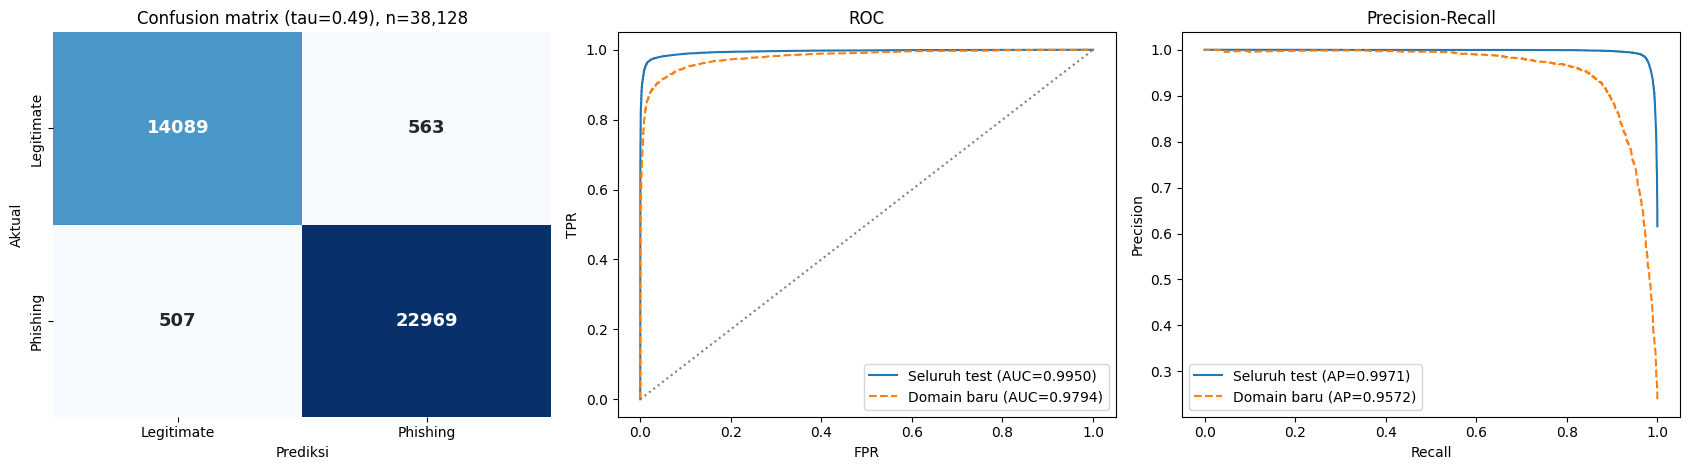

Waktu berjalan: 2.1 menit


In [ ]:
# ===================== EVALUASI HOLD-OUT (SATU KALI, MODEL TERPILIH SAJA) =====================
def evaluate(y, p, thr):
    pred = (p >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    two = len(np.unique(y)) == 2
    return dict(n=len(y), Accuracy=accuracy_score(y, pred), Precision=precision_score(y, pred, zero_division=0), Recall=recall_score(y, pred, zero_division=0),
                F1=f1_score(y, pred, zero_division=0), ROC_AUC=roc_auc_score(y, p) if two else np.nan, PR_AUC=average_precision_score(y, p) if two else np.nan,
                FPR=fp / max(fp + tn, 1), FNR=fn / max(fn + tp, 1), TN=tn, FP=fp, FN=fn, TP=tp)

best_model = MODEL_BUILDERS[BEST_NAME]()
t0 = time.perf_counter(); best_model.fit(X_train, y_train); fit_s = time.perf_counter() - t0
t0 = time.perf_counter(); p_test = best_model.predict_proba(X_test)[:, 1]; infer_ms = (time.perf_counter() - t0) * 1000

rows = []
for label, thr in [(f'tau OOF = {THR:.2f}', THR), ('tau = 0,50', 0.5)]:
    for sub, mask in [('Seluruh test', np.ones(len(y_test), bool)), ('Domain sudah ada di train', test_seen_mask), ('Domain BELUM pernah dilihat', ~test_seen_mask)]:
        if mask.sum() == 0: continue
        rows.append({'Ambang': label, 'Subset test': sub, **evaluate(y_test[mask], p_test[mask], thr)})
test_table = pd.DataFrame(rows)
print(f'=== EVALUASI HOLD-OUT: {BEST_NAME} | waktu fit {fit_s:.2f} s | inferensi {len(y_test):,} URL = {infer_ms:.1f} ms ===')
display(test_table.style.format({c: '{:.4f}' for c in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC', 'PR_AUC', 'FPR', 'FNR']}))

# interval kepercayaan bootstrap F1 (baris; indikatif karena baris sedalam domain yang sama tidak independen)
rng = np.random.default_rng(SEED); pred_main = (p_test >= THR).astype(int); boots = []
for _ in range(N_BOOT):
    ix = rng.integers(0, len(y_test), len(y_test)); boots.append(f1_score(y_test[ix], pred_main[ix], zero_division=0))
f1_ci = (np.percentile(boots, 2.5), np.percentile(boots, 97.5))
print(f'F1 test (tau OOF) = {f1_score(y_test, pred_main):.4f} | CI bootstrap 95% = [{f1_ci[0]:.4f}, {f1_ci[1]:.4f}]')

# ---- diagnostik shortcut: satu fitur path saja, dan ablasi fitur path ----
stump_rows = []
for f in ['pathlength', 'count_slashes']:
    if f in FEATURES:
        st = DecisionTreeClassifier(max_depth=1, random_state=SEED).fit(X_train[[f]], y_train)
        stump_rows.append({'Model': f'Decision stump: {f} saja', 'F1_test': f1_score(y_test, st.predict(X_test[[f]])), 'Acc_test': accuracy_score(y_test, st.predict(X_test[[f]]))})
PATH_GROUP = [f for f in ['pathlength', 'count_slashes', 'count_ques', 'queryparamcount', 'tokencount'] if f in FEATURES]
abl_rows = []
for label, drop in [('Semua fitur', []), ('Tanpa pathlength', ['pathlength']), (f'Tanpa kelompok path {PATH_GROUP}', PATH_GROUP)]:
    cols = [f for f in FEATURES if f not in drop]
    m = clone(best_model).fit(X_train[cols], y_train); p = m.predict_proba(X_test[cols])[:, 1]
    for sub, mask in [('Seluruh test', np.ones(len(y_test), bool)), ('Domain BELUM pernah dilihat', ~test_seen_mask)]:
        if mask.sum() == 0: continue
        e = evaluate(y_test[mask], p[mask], 0.5); abl_rows.append({'Skenario fitur': label, 'Subset test': sub, 'F1': e['F1'], 'ROC_AUC': e['ROC_AUC'], 'PR_AUC': e['PR_AUC']})
ablation_path = pd.DataFrame(abl_rows)
print('\n=== DIAGNOSTIK SHORTCUT (analisis, bukan dasar pemilihan model; ambang 0,50) ===')
display(pd.DataFrame(stump_rows).style.format({'F1_test': '{:.4f}', 'Acc_test': '{:.4f}'}))
display(ablation_path.style.format({'F1': '{:.4f}', 'ROC_AUC': '{:.4f}', 'PR_AUC': '{:.4f}'}))

# ---- visual ----
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
cm = confusion_matrix(y_test, pred_main, labels=[0, 1])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax[0], xticklabels=['Legitimate', 'Phishing'], yticklabels=['Legitimate', 'Phishing'], annot_kws={'size': 13, 'weight': 'bold'})
ax[0].set_title(f'Confusion matrix (tau={THR:.2f}), n={len(y_test):,}'); ax[0].set_xlabel('Prediksi'); ax[0].set_ylabel('Aktual')
for sub, mask, ls in [('Seluruh test', np.ones(len(y_test), bool), '-'), ('Domain baru', ~test_seen_mask, '--')]:
    if mask.sum() and len(np.unique(y_test[mask])) == 2:
        fpr, tpr, _ = roc_curve(y_test[mask], p_test[mask]); ax[1].plot(fpr, tpr, ls, label=f'{sub} (AUC={roc_auc_score(y_test[mask], p_test[mask]):.4f})')
        pr, rc, _ = precision_recall_curve(y_test[mask], p_test[mask]); ax[2].plot(rc, pr, ls, label=f'{sub} (AP={average_precision_score(y_test[mask], p_test[mask]):.4f})')
ax[1].plot([0, 1], [0, 1], ':', c='gray'); ax[1].set_xlabel('FPR'); ax[1].set_ylabel('TPR'); ax[1].set_title('ROC'); ax[1].legend(loc='lower right')
ax[2].set_xlabel('Recall'); ax[2].set_ylabel('Precision'); ax[2].set_title('Precision-Recall'); ax[2].legend(loc='lower left')
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'gambar_1_evaluasi_test_stage1.png'), dpi=250, bbox_inches='tight'); plt.show()

test_table.to_csv(os.path.join(OUT_DIR, 'tabel_2_test_stage1.csv'), index=False); ablation_path.to_csv(os.path.join(OUT_DIR, 'tabel_2b_ablasi_path.csv'), index=False)
joblib.dump(dict(model=best_model, name=BEST_NAME, features=FEATURES, threshold=THR), os.path.join(OUT_DIR, 'stage1_best_model.joblib'))
print(f'Waktu berjalan: {elapsed_min():.1f} menit')

### Cara membaca hasil hold-out dan diagnostik
* **Subset "domain belum pernah dilihat"** adalah estimasi yang lebih jujur untuk URL baru dari domain asing. Selisih F1 antara subset ini dan subset "domain sudah ada" mengukur seberapa besar skor keseluruhan ditopang oleh pengenalan platform.
* **Decision stump `pathlength`**: jika satu fitur tunggal sudah mendekati F1 model penuh, model sebagian besar belajar "halaman utama vs bukan halaman utama" (*shortcut*), bukan anatomi domain *phishing*. Ini wajib dibahas di paper.
* **Ablasi fitur path**: penurunan besar saat kelompok path dibuang menunjukkan ketergantungan pada struktur path; penurunan kecil menunjukkan fitur domain sendiri sudah informatif.
* Interval bootstrap dihitung pada level baris sehingga **terlalu sempit** untuk data yang berkelompok per domain; perlakukan sebagai indikasi.

---
# TAHAP 3: *Explainable AI* Tahap 1 (Gain, *Permutation*, SHAP)

Tiga metode dipakai karena masing-masing menjawab pertanyaan berbeda dan dapat saling bertentangan pada fitur yang berkorelasi:

* **Total *gain***: $\text{Gain}(j)=\sum_{k}\sum_{v\in V_k}G_{\text{split}}(v)\,\mathbb{I}[\text{feature}(v)=j]$ dan $\text{GainRatio}(j)=100\cdot\text{Gain}(j)/\sum_q \text{Gain}(q)$. Ini ukuran internal model, bukan kontribusi pada akurasi, dan bias terhadap fitur kontinu.
* ***Permutation importance***: $\text{PI}(j)=\text{F1}_{\text{dasar}}-\frac1R\sum_{r=1}^{R}\text{F1}_{r,j}^{\text{diacak}}$. Fitur yang saling menggantikan (mis. `urllength` dan `count_letters`) dapat tampak "tidak penting".
* **SHAP** (TreeSHAP): $f(x)=\phi_0+\sum_{j}\phi_j(x)$, $\phi_j=\sum_{S\subseteq F\setminus\{j\}}\frac{|S|!(M-|S|-1)!}{M!}[f_{S\cup\{j\}}(x)-f_S(x)]$, dan kepentingan global $\text{Mean}|\text{SHAP}|_j=\frac1n\sum_i|\phi_j(x_i)|$. Tanda $\phi_j>0$ mendorong ke kelas *phishing* pada skala log-odds. Arah global dibaca dari *beeswarm*, bukan dari Mean|SHAP|.

Analisis dilakukan pada **model terpilih** dan pada subsampel test (anggaran waktu). XAI menjelaskan perilaku model, bukan kausalitas, dan **tidak** dipakai untuk memilih ulang model atau fitur.

=== XAI TAHAP 1: LightGBM (Optuna Tuned) (SHAP pada 6,000 baris test, permutation pada 15,000 baris) ===


,Feature,Mean_Abs_SHAP,Total_Gain_Ratio_%,Permutation_F1_Drop,Permutation_F1_Drop_Std,Rank_SHAP,Rank_Gain,Rank_Perm,Korelasi_nilai_vs_SHAP
0,pathlength,2.7041,66.91,0.12480,0.00247,1,1,1,0.21
1,urllength,1.0594,4.76,0.02400,0.00092,2,4,2,0.49
2,count_non_alphanumeric,0.7450,0.81,-0.00016,0.00028,3,12,23,0.10
3,domainnamelength,0.6282,2.14,0.01913,0.00078,4,7,3,-0.69
4,urlentropy,0.5935,2.80,0.01086,0.00098,5,6,6,0.90
5,count_letters,0.4645,1.06,0.01199,0.00044,6,9,5,0.39
6,numberofdigits,0.4538,0.92,0.00550,0.00048,7,11,8,0.66
7,tokencount,0.3978,3.81,0.00499,0.00038,8,5,9,0.33
8,tldlength,0.3324,1.62,0.01006,0.00027,9,8,7,0.64
9,count_slashes,0.3004,6.19,0.00080,0.00034,10,3,14,0.52


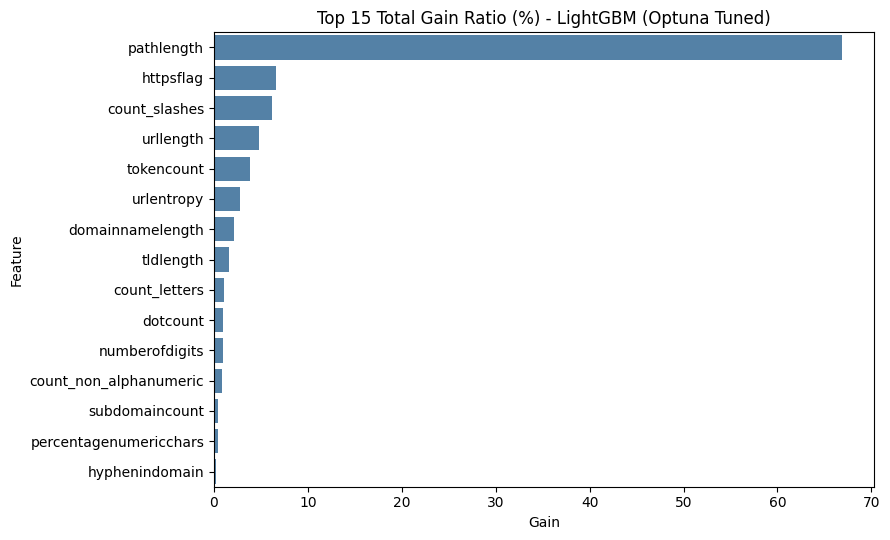

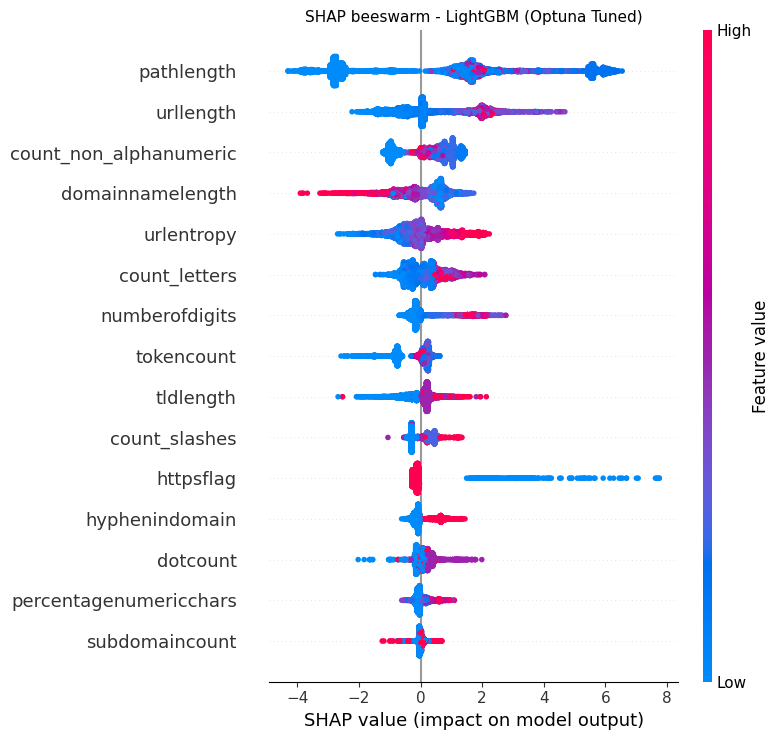

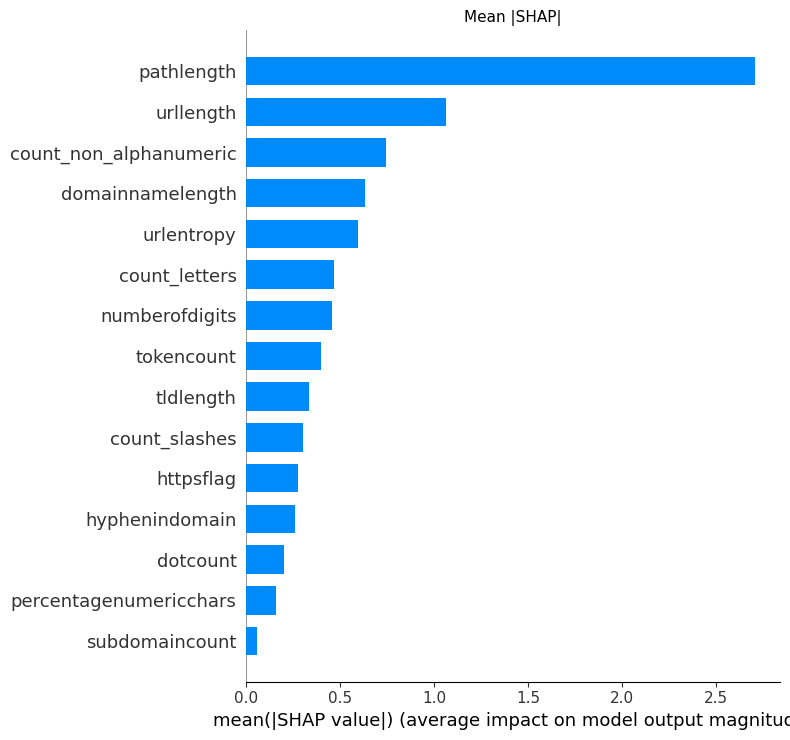

Arah pada beeswarm: titik di kanan (SHAP > 0) mendorong ke Phishing; titik di kiri mendorong ke Legitimate. Ini asosiasi yang dipakai model, bukan sebab-akibat.
Waktu berjalan: 2.6 menit


In [ ]:
# ===================== GAIN, PERMUTATION, SHAP (MODEL TERPILIH) =====================
if 'LightGBM' in BEST_NAME:
    gain_vals = best_model.booster_.feature_importance(importance_type='gain').astype(float)
else:
    sd = best_model.get_booster().get_score(importance_type='total_gain'); gain_vals = np.array([sd.get(f, 0.0) for f in FEATURES], dtype=float)
gain_ratio = gain_vals / gain_vals.sum() * 100 if gain_vals.sum() > 0 else np.zeros(len(FEATURES))

rs = np.random.RandomState(SEED)
ix_perm = rs.choice(len(X_test), min(PERM_SAMPLE, len(X_test)), replace=False)
perm = permutation_importance(best_model, X_test.iloc[ix_perm], y_test[ix_perm], n_repeats=PERM_REPEATS, random_state=SEED, scoring='f1', n_jobs=1)

ix_shap = rs.choice(len(X_test), min(SHAP_SAMPLE, len(X_test)), replace=False)
X_shap = X_test.iloc[ix_shap]
sv = shap.TreeExplainer(best_model)(X_shap); sv = np.asarray(sv.values)
shap_pos = sv[:, :, 1] if sv.ndim == 3 else sv
mean_abs_shap = np.abs(shap_pos).mean(axis=0)

fi_summary = pd.DataFrame({'Feature': FEATURES, 'Mean_Abs_SHAP': mean_abs_shap, 'Total_Gain_Ratio_%': gain_ratio,
                           'Permutation_F1_Drop': perm.importances_mean, 'Permutation_F1_Drop_Std': perm.importances_std}).sort_values('Mean_Abs_SHAP', ascending=False).reset_index(drop=True)
fi_summary['Rank_SHAP'] = np.arange(1, len(fi_summary) + 1)
fi_summary['Rank_Gain'] = fi_summary['Total_Gain_Ratio_%'].rank(ascending=False).astype(int)
fi_summary['Rank_Perm'] = fi_summary['Permutation_F1_Drop'].rank(ascending=False).astype(int)
# arah rata-rata (korelasi nilai fitur vs SHAP): indikatif, baca arah sebenarnya dari beeswarm
fi_summary['Korelasi_nilai_vs_SHAP'] = [np.corrcoef(X_shap[f], shap_pos[:, FEATURES.index(f)])[0, 1] if X_shap[f].std() > 0 else np.nan for f in fi_summary['Feature']]
print(f'=== XAI TAHAP 1: {BEST_NAME} (SHAP pada {len(X_shap):,} baris test, permutation pada {len(ix_perm):,} baris) ===')
display(fi_summary.head(15).style.format({'Mean_Abs_SHAP': '{:.4f}', 'Total_Gain_Ratio_%': '{:.2f}', 'Permutation_F1_Drop': '{:.5f}', 'Permutation_F1_Drop_Std': '{:.5f}', 'Korelasi_nilai_vs_SHAP': '{:.2f}'}))
fi_summary.to_csv(os.path.join(OUT_DIR, 'tabel_3_xai_stage1.csv'), index=False)

top = fi_summary.head(15)
plt.figure(figsize=(9, 5.5)); sns.barplot(data=pd.DataFrame({'Feature': FEATURES, 'Gain': gain_ratio}).sort_values('Gain', ascending=False).head(15), x='Gain', y='Feature', color='steelblue')
plt.title(f'Top 15 Total Gain Ratio (%) - {BEST_NAME}'); plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'gambar_2_gain.png'), dpi=250, bbox_inches='tight'); plt.show()
plt.figure(figsize=(9, 6.5)); shap.summary_plot(shap_pos, X_shap, max_display=15, show=False); plt.title(f'SHAP beeswarm - {BEST_NAME}', fontsize=11)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'gambar_3_shap_beeswarm.png'), dpi=250, bbox_inches='tight'); plt.show()
plt.figure(figsize=(9, 5.5)); shap.summary_plot(shap_pos, X_shap, plot_type='bar', max_display=15, show=False); plt.title('Mean |SHAP|', fontsize=11)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'gambar_4_shap_bar.png'), dpi=250, bbox_inches='tight'); plt.show()
print('Arah pada beeswarm: titik di kanan (SHAP > 0) mendorong ke Phishing; titik di kiri mendorong ke Legitimate. Ini asosiasi yang dipakai model, bukan sebab-akibat.')
print(f'Waktu berjalan: {elapsed_min():.1f} menit')

### Cara menulis pembahasan XAI Tahap 1
1. Baca 5 fitur teratas dari **ketiga** metode dan sebutkan yang konsisten serta yang bertentangan (`Rank_SHAP`, `Rank_Gain`, `Rank_Perm`). Pertentangan biasanya menandakan fitur berkorelasi.
2. Arah pengaruh **harus diperiksa pada *beeswarm***. Jangan menyalin narasi dataset lama (misalnya "domain *phishing* lebih panjang"): pada data baru arah dan besarnya dapat berubah, dan nilai rata-rata fitur per kelas perlu dihitung ulang dari data aktual.
3. Hubungkan dengan **diagnostik *shortcut*** pada Tahap 2 dan audit Tahap 0: bila fitur path/jumlah garis miring mendominasi, tulis bahwa model sebagian besar membedakan "halaman utama vs halaman dalam pada platform hosting/pemendek tautan".
4. Gain bukan persentase akurasi; SHAP bukan sebab-akibat.

---
# TAHAP 4: Korpus Tahap 2 dan Jangkar Kata Kunci

**Korpus latih** adalah URL berlabel *phishing* asli pada train (bukan prediksi model), karena Tahap 2 tidak boleh belajar dari kesalahan Tahap 1. **Uji ujung-ke-ujung** memakai URL test yang **diprediksi *phishing*** oleh model Tahap 1 pada ambang $\tau^*$; sebagian di antaranya adalah *legitimate* yang salah ditandai (*error propagation*), dan dampaknya dilaporkan.

**Jangkar:** karena label *job phishing* tidak ada dan 7.873 URL lama tidak dipakai, jangkar hanya berupa kata kunci rekrutmen pada string URL (*strict*: `job, career, recruit, hiring, vacanc, lowongan, karir, loker, employ, resume, internship`; *loose*: token utuh seperti `apply, talent, staff, position, cv`). Jangkar ini **deskriptif**:

* ia **bukan** label dan **tidak boleh** dipakai sebagai satu-satunya bukti validitas klaster (sirkularitas: klaster dinilai dengan kata kunci yang sama dengan yang menandai klaster);
* sebagian URL berkata kunci bukan penipuan lowongan (mis. situs pembuat resume yang disalahgunakan, atau kata Spanyol *resumen*);
* jumlahnya sangat kecil (kurang dari 1% dari URL *phishing*), sehingga klaster berukuran besar kemungkinan mengikuti **platform hosting**, bukan niat.

In [ ]:
phish_df = train_df[train_df['ClassLabel'] == 1].reset_index(drop=True)
pp_mask = p_test >= THR                                   # URL test yang diprediksi phishing oleh model Tahap 1
test_pp = test_df[pp_mask].reset_index(drop=True); test_pp_y = y_test[pp_mask]

STRICT_RE = re.compile(r'job|career|recruit|hiring|vacanc|lowongan|karir|loker|employ|resume|internship|cakeresume|linkedin|indeed|jobstreet|glassdoor|workday|greenhouse|bamboohr')
LOOSE_TOKENS = {'apply', 'application', 'talent', 'staff', 'position', 'opening', 'salary', 'cv', 'intern', 'work', 'workers', 'workspace', 'hr', 'portal', 'jotform', 'hsforms', 'typeform', 'viewform', 'abcsubmit'}
def anchor_strict(urls): return np.array([bool(STRICT_RE.search(str(u).lower())) for u in urls])
def anchor_loose(urls):  return np.array([bool(LOOSE_TOKENS & set(re.findall(r'[a-z0-9]+', str(u).lower()))) for u in urls])

anc_tr = anchor_strict(phish_df['URL']); anc_tr_loose = anchor_loose(phish_df['URL']) | anc_tr
anc_te_pp = anchor_strict(test_pp['URL']); anc_te_loose = anchor_loose(test_pp['URL']) | anc_te_pp
legit_tr = train_df[train_df['ClassLabel'] == 0]
cnt = pd.DataFrame([
    ('Phishing train (korpus latih AE)', len(phish_df), anc_tr.sum(), anc_tr_loose.sum()),
    ('Legitimate train (pembanding)', len(legit_tr), anchor_strict(legit_tr['URL']).sum(), (anchor_loose(legit_tr['URL']) | anchor_strict(legit_tr['URL'])).sum()),
    ('Test diprediksi phishing oleh ' + BEST_NAME + ' (uji ujung-ke-ujung)', len(test_pp), anc_te_pp.sum(), anc_te_loose.sum()),
], columns=['Himpunan', 'n URL', 'Jangkar strict (Job/Career)', 'Jangkar gabungan (Job/Form/Portal)'])
cnt['% strict'] = (cnt['Jangkar strict (Job/Career)'] / cnt['n URL'] * 100).round(3)
cnt['% gabungan'] = (cnt['Jangkar gabungan (Job/Form/Portal)'] / cnt['n URL'] * 100).round(3)
display(cnt)
print(f'URL test diprediksi phishing: {len(test_pp):,} | di antaranya sebenarnya legitimate (error propagation): {(test_pp_y == 0).sum():,} ({(test_pp_y == 0).mean():.2%})')
print('Contoh URL berjangkar strict (phishing train):'); print(phish_df.loc[anc_tr, 'URL'].head(8).tolist())
cnt.to_csv(os.path.join(OUT_DIR, 'tabel_4_korpus_jangkar.csv'), index=False)

,Himpunan,n URL,Jangkar strict (Job/Career),Jangkar gabungan (Job/Form/Portal),% strict,% gabungan
0,Phishing train (korpus latih AE),38305,67,867,0.175,2.263
1,Legitimate train (pembanding),39931,89,147,0.223,0.368
2,Test diprediksi phishing oleh LightGBM (Optuna...,23532,57,667,0.242,2.834


URL test diprediksi phishing: 23,532 | di antaranya sebenarnya legitimate (error propagation): 563 (2.39%)
Contoh URL berjangkar strict (phishing train):
['https://geicorecruiters.us-mia-1.linodeobjects.com/Linkedinpage.html', 'https://www.cakeresume.com/s--qLDzocKp83eiJhM5mvFyQA--/at-t-0f3181', 'https://storage.ghost.io/c/f5/c8/f5c8d86e-a923-41f2-b598-72858788c697/content/files/2023/08/21-Lessons---Resumen-por-Iva-n-Pa-rraga.pdf', 'https://resume.io/r/53CgUbJy9', 'https://wondrous-employees-526779.framer.app/', 'https://www.cakeresume.com/nathalie-pean', 'https://bafkreid6ze67djobib5pnyqtwlmzmyqyd2n4e7uauu233rjt247ymbf5ai.ipfs.dweb.link/', 'https://lasyaja.github.io/linkedin-login-clone/']


---
# TAHAP 5: Tokenisasi URL

Fitur numerik hanya menangkap "kerangka ukuran" URL; dua URL dengan panjang domain, jumlah tanda hubung, dan jumlah garis miring yang sama dapat memiliki tujuan berbeda. Tokenisasi memungkinkan model membaca **muatan kata**.

**Langkah:**
1. Normalisasi: huruf kecil, buang skema dan `www.`, buang kode `%xx`, potong 400 karakter pertama.
2. **Placeholder** agar token acak tidak mendominasi kosakata: deret heksadesimal $\ge 16$ karakter → `[HEX]`; token alfanumerik $\ge 12$ karakter yang memuat huruf dan angka → `[ID]`; setiap deret angka → `[NUM]`.
3. **BPE** (*byte-pair encoding*) pada kosakata `VOCAB`, dengan pra-tokenisasi pada spasi dan tanda baca (`/ . - _ ? = & : @`). Tokenizer **dilatih hanya pada korpus *phishing* train**.
4. Sekuens diawali `[CLS]`, dipotong/di-*pad* ke `MAX_LEN` token. Karena bagian domain berada di awal URL, pemotongan menjaga informasi domain dan awal path.

In [ ]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, normalizers
SPECIAL = ['[PAD]', '[UNK]', '[CLS]', '[MASK]', '[HEX]', '[ID]', '[NUM]']

def url_to_text(u):
    s = SCHEME_RE.sub('', str(u).strip().lower()); s = re.sub(r'^www\d*\.', '', s)[:400]
    s = re.sub(r'%[0-9a-f]{2}', ' ', s)
    def _mask(m):
        w = m.group(0)
        if re.fullmatch(r'[0-9a-f]{16,}', w): return ' [HEX] '
        if len(w) >= 12 and re.search(r'\d', w) and re.search(r'[a-z]', w): return ' [ID] '
        return w
    s = re.sub(r'[a-z0-9]{12,}', _mask, s)
    return re.sub(r'\d+', ' [NUM] ', s)

texts_tr = [url_to_text(u) for u in phish_df['URL']]
texts_te = [url_to_text(u) for u in test_pp['URL']]

tok = Tokenizer(models.BPE(unk_token='[UNK]'))
tok.normalizer = normalizers.Lowercase()
tok.pre_tokenizer = pre_tokenizers.Sequence([pre_tokenizers.WhitespaceSplit(), pre_tokenizers.Punctuation(behavior='isolated')])
tok.train_from_iterator(texts_tr, trainers.BpeTrainer(vocab_size=VOCAB, min_frequency=3, special_tokens=SPECIAL, show_progress=False))
V = tok.get_vocab_size(); PAD_ID, CLS_ID, MASK_ID = tok.token_to_id('[PAD]'), tok.token_to_id('[CLS]'), tok.token_to_id('[MASK]'); N_SPECIAL = len(SPECIAL)
ID2TOK = {i: tok.id_to_token(i) for i in range(V)}

def encode_texts(texts):
    enc = tok.encode_batch(texts); ids = np.zeros((len(texts), MAX_LEN), dtype=np.int64); lens = []
    for i, e in enumerate(enc):
        seq = [CLS_ID] + e.ids[:MAX_LEN - 1]; ids[i, :len(seq)] = seq; lens.append(len(e.ids))
    return ids, np.array(lens)

ids_tr, len_tr = encode_texts(texts_tr); ids_te, len_te = encode_texts(texts_te)
print(f'Kosakata BPE: {V} | panjang token: median {np.median(len_tr):.0f}, p95 {np.percentile(len_tr, 95):.0f} | terpotong (> {MAX_LEN - 1} token): {(len_tr > MAX_LEN - 1).mean():.2%}')
for i in list(np.where(anc_tr)[0][:3]) + [0, 1]:
    print(phish_df.loc[i, 'URL'][:90], '->', [ID2TOK[t] for t in ids_tr[i] if t != PAD_ID][:18])
tok.save(os.path.join(OUT_DIR, 'tokenizer_bpe.json'))

# fitur untuk cabang numerik: log1p lalu StandardScaler (dilatih hanya pada korpus latih)
def feat_tf(df): return np.log1p(df[FEATURES].clip(lower=0).to_numpy(dtype=np.float64))
feat_scaler = StandardScaler().fit(feat_tf(phish_df))
feats_tr = np.clip(feat_scaler.transform(feat_tf(phish_df)), -6, 6).astype(np.float32)
feats_te = np.clip(feat_scaler.transform(feat_tf(test_pp)), -6, 6).astype(np.float32)
joblib.dump(feat_scaler, os.path.join(OUT_DIR, 'stage2_feature_scaler.joblib'))

Kosakata BPE: 6000 | panjang token: median 10, p95 30 | terpotong (> 63 token): 0.39%
https://geicorecruiters.us-mia-1.linodeobjects.com/Linkedinpage.html -> ['[CLS]', 'ge', 'i', 'core', 'cr', 'uit', 'ers', '.', 'us', '-', 'm', 'ia', '-', '[NUM]', '.', 'lin', 'ode', 'object']
https://www.cakeresume.com/s--qLDzocKp83eiJhM5mvFyQA--/at-t-0f3181 -> ['[CLS]', 'cakeresume', '.', 'com', '/', 's', '-', '-', '[ID]', '-', '-', '/', 'at', '-', 't', '-', '[NUM]', 'f']
https://storage.ghost.io/c/f5/c8/f5c8d86e-a923-41f2-b598-72858788c697/content/files/2023/0 -> ['[CLS]', 'storage', '.', 'ghost', '.', 'io', '/', 'c', '/', 'f', '[NUM]', '/', 'c', '[NUM]', '/', 'f', '[NUM]', 'c']
https://avanzapich1ncha.webcindario.com/ -> ['[CLS]', '[ID]', '.', 'webcindario', '.', 'com', '/']
https://winpreisu12.web.app/ -> ['[CLS]', 'win', 'pre', 'is', 'u', '[NUM]', '.', 'web', '.', 'app', '/']


['/content/drive/MyDrive/ICDSOS/hasil_pipeline_v2/stage2_feature_scaler.joblib']

---
# TAHAP 6: *Hybrid Multimodal Self-Attention Autoencoder* Tanpa Label

## 6.1 Arsitektur Dua Cabang (*Hybrid Multimodal*)
Untuk menjawab kelemahan jika hanya memakai teks saja atau 23 fitur numerik saja, model `URLAE` dirancang sebagai **Hybrid Multimodal Self-Attention Autoencoder** yang memadukan kedua modalitas pada subset URL *phishing*:

1. **Cabang 1 — *URL Tokenization, Multi-Head Self-Attention, & Explicit Attention Pooling*:**
   Setiap sekuens token BPE $t_{1:L}$ dipetakan ke $E = \text{Emb}(t) + \text{Pos}$, lalu diproses oleh `N_LAYER` blok Transformer (*Pre-LayerNorm*, *Multi-Head Self-Attention*, dan *Feed-Forward Network*):
   $$\text{Attn}(Q, K, V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$
   Di atas keluaran kontekstual $H \in \mathbb{R}^{L \times d}$, diterapkan lapisan **Explicit Token Self-Attention Pooling** yang menghitung bobot perhatian ($\alpha_j$) untuk setiap token aktif:
   $$\alpha_j = \frac{\exp\left(\mathbf{w}_a^\top \tanh(\mathbf{W}_a \mathbf{H}_j)\right)}{\sum_{m=1}^{L} \mathbb{I}(t_m \neq \text{PAD}) \exp\left(\mathbf{w}_a^\top \tanh(\mathbf{W}_a \mathbf{H}_m)\right)}, \qquad \mathbf{h}_{\text{attn}} = \sum_{j=1}^{L} \alpha_j \mathbf{H}_j$$
   Representasi semantik Cabang 1 digabungkan sebagai $\mathbf{h}_{\text{sem}} = [\mathbf{H}_{\text{CLS}};\, \mathbf{h}_{\text{attn}}] \in \mathbb{R}^{2d}$.
2. **Cabang 2 — *Dense Encoder 23 Fitur Numerik Leksikal & Struktural*:**
   Vektor 23 fitur aktif $\mathbf{x} \in \mathbb{R}^{23}$ (yang telah ditransformasi $\log(1+x)$ dan `StandardScaler`) diproses oleh *Dense MLP Encoder* untuk menghasilkan representasi struktur fisik URL $\mathbf{u}_{\text{struct}} = \text{MLP}(\mathbf{x}) \in \mathbb{R}^{64}$.
3. **Fusi Multimodal ke *Bottleneck Latent Space* ($\mathbf{z} \in \mathbb{R}^{16}$):**
   Kedua cabang digabungkan ke dalam lapisan penyempitan (*bottleneck*):
   $$\mathbf{z} = \text{MLP}\left([\mathbf{h}_{\text{sem}};\, \mathbf{u}_{\text{struct}}]\right) \in \mathbb{R}^{Z}$$

## 6.2 Tiga Fungsi Kerugian *Self-Supervised* (*Denoising Multimodal Autoencoder*)
Sebagian token ($p = 15\%$) disamarkan menjadi `[MASK]` ($80\%$), token acak ($10\%$), atau dipertahankan ($10\%$), kemudian jaringan dilatih meminimalkan gabungan tiga fungsi kerugian tanpa label kelas:
$$\mathcal{L} = \underbrace{-\frac{1}{|M|}\sum_{i\in M}\log p_\theta(t_i\mid \tilde{t})}_{\mathcal{L}_{\text{MLM}}\text{ (konteks token)}} + \lambda_b\underbrace{\left(-\sum_{v=1}^{V} q_v \log \text{softmax}(W_b\mathbf{z})_v\right)}_{\mathcal{L}_{\text{BoW}}\text{ (muatan kata di }\mathbf{z}\text{)}} + \lambda_f\underbrace{\left\|\mathbf{x} - g(\mathbf{z})\right\|_2^2}_{\mathcal{L}_{\text{Feat}}\text{ (struktur 23 fitur di }\mathbf{z}\text{)}}$$

## 6.3 Skema Klasterisasi Ganda: Pemisahan Biner ($k=2$: *Job Phishing* vs. *Non-Job Phishing*) & Pemilihan $k$ Optimal
* **Pemisahan Biner ($k = 2$)**: Sesuai tujuan utama tim, vektor laten $\mathbf{z}$ pada URL *phishing* (baik pada korpus *train* maupun pada prediksi *phishing* dari model terbaik `LightGBM Optuna Tuned` di data *test*) dikelompokkan menjadi **2 klaster utama** (`Job / Recruitment-Oriented Phishing` vs. `Non-Job / General Phishing`) berdasarkan pengayaan sinyal leksikal/formulir rekrutmen dan profil fitur strukturalnya.
* **Eksplorasi Multi-Klaster ($k \in \{2, \dots, 8\}$) & Ablasi Multimodal**: Untuk menjaga ketajaman analisis ilmiah, dilakukan pula evaluasi stabilitas *Adjusted Rand Index* (ARI) antar-*seed*, *Silhouette Score*, dan *Davies-Bouldin Index* pada rentang $k \in \{2, \dots, 8\}$, disertai studi ablasi antara varian **`hybrid` (Token + 23 Fitur)**, **`tok` (Token saja)**, dan **`feat` (23 Fitur saja)**.

In [ ]:
# ===================== DEFINISI MODEL HYBRID MULTIMODAL SELF-ATTENTION AE =====================
class MHSA(nn.Module):
    def __init__(s, d, h, p):
        super().__init__(); s.h, s.dk = h, d // h; s.qkv = nn.Linear(d, 3 * d); s.o = nn.Linear(d, d); s.drop = nn.Dropout(p)
    def forward(s, x, mask, return_attn=False):
        B, L, D = x.shape
        q, k, v = s.qkv(x).view(B, L, 3, s.h, s.dk).permute(2, 0, 3, 1, 4)
        att = (q @ k.transpose(-2, -1)) / math.sqrt(s.dk)
        att = att.masked_fill(~mask[:, None, None, :], torch.finfo(att.dtype).min).softmax(-1)
        out = (s.drop(att) @ v).transpose(1, 2).reshape(B, L, D)
        return s.o(out), (att if return_attn else None)

class Block(nn.Module):
    def __init__(s, d, h, ff, p):
        super().__init__(); s.ln1, s.ln2 = nn.LayerNorm(d), nn.LayerNorm(d); s.att = MHSA(d, h, p)
        s.ff = nn.Sequential(nn.Linear(d, ff), nn.GELU(), nn.Dropout(p), nn.Linear(ff, d)); s.drop = nn.Dropout(p)
    def forward(s, x, mask, return_attn=False):
        a, att = s.att(s.ln1(x), mask, return_attn); x = x + s.drop(a)
        return x + s.drop(s.ff(s.ln2(x))), att

class URLAE(nn.Module):
    def __init__(s, vocab, n_feat, use_tok=True, use_feat=True):
        super().__init__(); s.use_tok, s.use_feat, s.V = use_tok, use_feat, vocab; d = D_MODEL
        if use_tok:
            s.tok_emb = nn.Embedding(vocab, d, padding_idx=PAD_ID); s.pos_emb = nn.Embedding(MAX_LEN, d)
            s.blocks = nn.ModuleList([Block(d, N_HEAD, D_FF, DROPOUT) for _ in range(N_LAYER)]); s.ln = nn.LayerNorm(d)
            # Explicit Token Self-Attention Pooling layer untuk pembobotan langsung setiap token URL
            s.attn_pool = nn.Sequential(nn.Linear(d, d // 2), nn.Tanh(), nn.Linear(d // 2, 1))
            s.mlm_head = nn.Linear(d, vocab); s.bow_head = nn.Linear(Z_DIM, vocab)
        if use_feat:
            s.feat_enc = nn.Sequential(nn.Linear(n_feat, 128), nn.LayerNorm(128), nn.GELU(), nn.Linear(128, 64), nn.GELU())
            s.feat_dec = nn.Sequential(nn.Linear(Z_DIM, 64), nn.GELU(), nn.Linear(64, n_feat))
        s.to_z = nn.Sequential(nn.Linear((2 * d if use_tok else 0) + (64 if use_feat else 0), 128), nn.LayerNorm(128), nn.GELU(), nn.Linear(128, Z_DIM))

    def encode(s, ids, feats, return_attn=False):
        parts, H, attns = [], None, []
        if s.use_tok:
            B, L = ids.shape; mask = ids != PAD_ID
            x = s.tok_emb(ids) + s.pos_emb(torch.arange(L, device=ids.device))[None]
            for blk in s.blocks:
                x, a = blk(x, mask, return_attn); attns.append(a)
            H = s.ln(x)
            # Hitung bobot perhatian eksplisit (alpha) pada token non-PAD
            scores = s.attn_pool(H).squeeze(-1)
            scores = scores.masked_fill(~mask, torch.finfo(scores.dtype).min)
            alpha = scores.softmax(dim=-1)
            h_attn = (H * alpha.unsqueeze(-1)).sum(dim=1)
            parts += [H[:, 0], h_attn]
            if return_attn:
                s.last_pool_alpha = alpha.detach()
        if s.use_feat: parts.append(s.feat_enc(feats))
        return s.to_z(torch.cat([p.float() for p in parts], -1)), H, attns

    def loss(s, ids, feats):
        tot, parts = 0.0, {}
        if s.use_tok:
            valid = (ids != PAD_ID) & (ids != CLS_ID); sel = (torch.rand(ids.shape, device=ids.device) < MASK_P) & valid
            r = torch.rand(ids.shape, device=ids.device); inp = ids.clone()
            inp[sel & (r < 0.8)] = MASK_ID
            inp = torch.where(sel & (r >= 0.8) & (r < 0.9), torch.randint(N_SPECIAL, s.V, ids.shape, device=ids.device), inp)
        else:
            inp = ids
        z, H, _ = s.encode(inp, feats)
        if s.use_tok:
            mlm = F.cross_entropy(s.mlm_head(H[sel]).float(), ids[sel]) if sel.any() else z.sum() * 0
            tgt = torch.zeros(ids.shape[0], s.V, device=ids.device).scatter_add_(1, ids, valid.float()); tgt = tgt / tgt.sum(1, keepdim=True).clamp(min=1)
            bow = -(tgt * F.log_softmax(s.bow_head(z).float(), -1)).sum(1).mean()
            tot = tot + mlm + LAMBDA_BOW * bow; parts.update(mlm=float(mlm), bow=float(bow))
        if s.use_feat:
            fr = F.mse_loss(s.feat_dec(z).float(), feats); tot = tot + LAMBDA_FEAT * fr; parts['feat'] = float(fr)
        return tot, parts

VARIANTS = {'hybrid': dict(use_tok=True, use_feat=True), 'tok': dict(use_tok=True, use_feat=False), 'feat': dict(use_tok=False, use_feat=True)}
AMP_DTYPE = torch.bfloat16 if (DEVICE == 'cuda' and torch.cuda.is_bf16_supported()) else torch.float16

def train_ae(variant, seed):
    set_seed(seed); model = URLAE(V, feats_tr.shape[1], **VARIANTS[variant]).to(DEVICE)
    x_all = torch.as_tensor(ids_tr, device=DEVICE); f_all = torch.as_tensor(feats_tr, device=DEVICE); N = len(x_all)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    steps = EPOCHS * math.ceil(N / BATCH); sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=steps, pct_start=0.1)
    scaler_amp = torch.cuda.amp.GradScaler(enabled=(DEVICE == 'cuda' and AMP_DTYPE == torch.float16))
    hist = []
    for ep in range(EPOCHS):
        model.train(); perm = torch.randperm(N, device=DEVICE); acc = {}
        for b in range(0, N, BATCH):
            ix = perm[b:b + BATCH]
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE, dtype=AMP_DTYPE, enabled=(DEVICE == 'cuda')):
                loss, parts = model.loss(x_all[ix], f_all[ix])
            if scaler_amp.is_enabled():
                scaler_amp.scale(loss).backward()
                scaler_amp.unscale_(opt)
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler_amp.step(opt); scaler_amp.update()
            else:
                loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            sched.step()
            for k_, v_ in parts.items(): acc[k_] = acc.get(k_, 0) + v_ * len(ix)
        hist.append({k_: v_ / N for k_, v_ in acc.items()})
        if ep % 5 == 0 or ep == EPOCHS - 1: print(f'  [{variant} s{seed}] epoch {ep + 1}/{EPOCHS}', {k_: round(v_, 4) for k_, v_ in hist[-1].items()})
    return model, hist

@torch.no_grad()
def embed(model, ids_np, feats_np, bs=2048):
    model.eval(); out = []
    for b in range(0, len(ids_np), bs):
        z = model.encode(torch.as_tensor(ids_np[b:b + bs], device=DEVICE), torch.as_tensor(feats_np[b:b + bs], device=DEVICE))[0]
        out.append(z.float().cpu().numpy())
    return np.concatenate(out)

EMB = {}      # (variant, seed) -> (Z_train, Z_testpred)
def get_embeddings(variant, seed):
    key = (variant, seed)
    if key in EMB: return EMB[key]
    path = os.path.join(OUT_DIR, f'emb_{variant}_s{seed}.npz')
    if os.path.exists(path):
        d = np.load(path); EMB[key] = (d['z_tr'], d['z_te']); print(f'  [{variant} s{seed}] embedding dimuat dari checkpoint'); return EMB[key]
    t0 = time.time(); model, hist = train_ae(variant, seed)
    EMB[key] = (embed(model, ids_tr, feats_tr), embed(model, ids_te, feats_te))
    np.savez_compressed(path, z_tr=EMB[key][0], z_te=EMB[key][1]); torch.save(model.state_dict(), os.path.join(OUT_DIR, f'ae_{variant}_s{seed}.pt'))
    pd.DataFrame(hist).to_csv(os.path.join(OUT_DIR, f'loss_{variant}_s{seed}.csv'), index=False)
    print(f'  [{variant} s{seed}] selesai dalam {time.time() - t0:.0f} detik'); return EMB[key]
print('Definisi model Hybrid Multimodal Self-Attention AE siap. Total parameter:', sum(p.numel() for p in URLAE(V, feats_tr.shape[1]).parameters()))

Definisi model Hybrid Multimodal Self-Attention AE siap. Total parameter: 2115784


=== MELATIH HYBRID (token + fitur), tanpa label ===
  [hybrid s0] embedding dimuat dari checkpoint
  [hybrid s1] embedding dimuat dari checkpoint
  [hybrid s2] embedding dimuat dari checkpoint
Waktu berjalan: 2.7 menit
=== PEMILIHAN k (hybrid; aturan: ARI antar-seed tertinggi, lalu silhouette) ===


,k,ARI_antar_seed,Silhouette,Davies_Bouldin
0,2,0.8435,0.2356,1.4238
1,3,0.6016,0.2034,2.0610
2,4,0.4436,0.2026,1.8707
3,5,0.4487,0.2065,1.7524
4,6,0.4568,0.1996,1.6924
5,7,0.4201,0.2059,1.6657
6,8,0.3848,0.2043,1.6492


k terpilih = 2


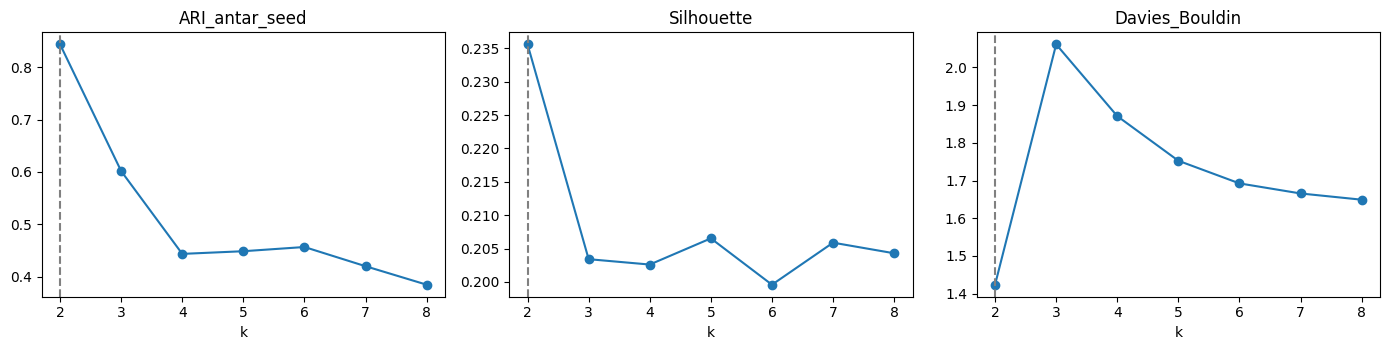

In [ ]:
# ===================== LATIH HYBRID (BEBERAPA SEED) + PEMILIHAN k =====================
import itertools
print('=== MELATIH HYBRID (token + fitur), tanpa label ===')
for s in SEEDS: get_embeddings('hybrid', s)
print(f'Waktu berjalan: {elapsed_min():.1f} menit')

def km_fit(Z, k, seed):
    sc = StandardScaler().fit(Z); km = KMeans(n_clusters=k, n_init=5, random_state=SEED + seed).fit(sc.transform(Z)); return sc, km
rng_sil = np.random.RandomState(SEED); sil_idx = rng_sil.choice(len(ids_tr), min(SIL_SAMPLE, len(ids_tr)), replace=False)

ksel_rows, labels_cache = [], {}
for k in K_RANGE:
    labs, sils, dbis = [], [], []
    for s in SEEDS:
        Z = EMB[('hybrid', s)][0]; sc, km = km_fit(Z, k, s); Zs = sc.transform(Z); lab = km.labels_
        labs.append(lab); labels_cache[(k, s)] = lab
        sils.append(silhouette_score(Zs[sil_idx], lab[sil_idx]) if len(np.unique(lab[sil_idx])) > 1 else np.nan); dbis.append(davies_bouldin_score(Zs, lab))
    aris = [adjusted_rand_score(a, b) for a, b in itertools.combinations(labs, 2)]
    ksel_rows.append(dict(k=k, ARI_antar_seed=np.mean(aris), Silhouette=np.nanmean(sils), Davies_Bouldin=np.mean(dbis)))
ksel = pd.DataFrame(ksel_rows)
K_SEL = int(ksel.sort_values(['ARI_antar_seed', 'Silhouette'], ascending=False).iloc[0]['k'])
print('=== PEMILIHAN k (hybrid; aturan: ARI antar-seed tertinggi, lalu silhouette) ===')
display(ksel.style.format({'ARI_antar_seed': '{:.4f}', 'Silhouette': '{:.4f}', 'Davies_Bouldin': '{:.4f}'}).apply(lambda r: ['background-color: #dff0d8' if r['k'] == K_SEL else '' for _ in r], axis=1))
print(f'k terpilih = {K_SEL}')
ksel.to_csv(os.path.join(OUT_DIR, 'tabel_5_pemilihan_k.csv'), index=False)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for a_, col in zip(ax, ['ARI_antar_seed', 'Silhouette', 'Davies_Bouldin']):
    a_.plot(ksel['k'], ksel[col], 'o-'); a_.axvline(K_SEL, ls='--', c='gray'); a_.set_title(col); a_.set_xlabel('k')
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'gambar_5_pemilihan_k.png'), dpi=220, bbox_inches='tight'); plt.show()

In [ ]:
# ===================== VARIAN ABLASI + PEMBANDING, PADA k TERPILIH =====================
def anchor_table(lab, anc):
    n_tot, a_tot, rows = len(lab), int(anc.sum()), []
    for c in sorted(np.unique(lab)):
        m = lab == c; n_c, a_c = int(m.sum()), int(anc[m].sum())
        rows.append(dict(klaster=c, n=n_c, persen=100 * n_c / n_tot, jangkar=a_c, jangkar_persen=100 * a_c / max(n_c, 1),
                         lift=(a_c / max(n_c, 1)) / (a_tot / n_tot) if a_tot else np.nan, p_hipergeom=hypergeom.sf(a_c - 1, n_tot, a_tot, n_c) if a_tot else np.nan))
    return pd.DataFrame(rows)

SPACES, LABELS_BY_VARIANT = {}, {}      # variant -> {seed: Z standardized}, variant -> {seed: labels}
def register(variant, Zs_by_seed):
    LABELS_BY_VARIANT[variant], SPACES[variant] = {}, {}
    for s, Z in Zs_by_seed.items():
        sc, km = km_fit(Z, K_SEL, s); SPACES[variant][s] = sc.transform(Z); LABELS_BY_VARIANT[variant][s] = km.labels_

register('hybrid', {s: EMB[('hybrid', s)][0] for s in SEEDS})
if elapsed_min() < SOFT_LIMIT_MIN:
    print('=== ABLASI: token saja dan fitur saja ===')
    for v in ['tok', 'feat']:
        for s in SEEDS: get_embeddings(v, s)
        register(v, {s: EMB[(v, s)][0] for s in SEEDS})
else:
    print('Batas waktu lunak terlewati: ablasi neural dilewati.')

if elapsed_min() < SOFT_LIMIT_MIN:
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.decomposition import TruncatedSVD
    from sklearn.preprocessing import Normalizer
    tf = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), max_features=50000 if not SMOKE_TEST else 3000, sublinear_tf=True, dtype=np.float32)
    Xtf = tf.fit_transform(texts_tr); Ztf = Normalizer().fit_transform(TruncatedSVD(n_components=min(64, Xtf.shape[1] - 1), random_state=SEED).fit_transform(Xtf))
    register('tfidf_char', {s: Ztf for s in SEEDS}); register('fitur_mentah', {s: feats_tr for s in SEEDS})
    print('Pembanding TF-IDF char n-gram dan fitur mentah selesai.')

abl_rows = []
for v, labs in LABELS_BY_VARIANT.items():
    ss = sorted(labs); aris = [adjusted_rand_score(labs[a], labs[b]) for a, b in itertools.combinations(ss, 2)]
    sil = [silhouette_score(SPACES[v][s][sil_idx], labs[s][sil_idx]) for s in ss]; at = anchor_table(labs[ss[0]], anc_tr)
    abl_rows.append(dict(Varian=v, k=K_SEL, ARI_antar_seed=np.mean(aris), Silhouette_ruang_sendiri=np.mean(sil),
                         Ukuran_klaster_terbesar_persen=at['persen'].max(), Lift_jangkar_maks=at['lift'].max()))
ablation_clusters = pd.DataFrame(abl_rows)
print(f'=== ABLASI & PEMBANDING (k = {K_SEL}) ===')
display(ablation_clusters.style.format({c: '{:.4f}' for c in ablation_clusters.columns if c not in ('Varian', 'k')}))
print('Catatan: silhouette antar-varian tidak sepenuhnya sebanding (ruang berbeda), dan "lift jangkar" hanya deskriptif (sirkular). Perbandingan yang sah antar-varian adalah terhadap LABEL MANUAL pada Tahap 7.')
ablation_clusters.to_csv(os.path.join(OUT_DIR, 'tabel_6_ablasi_klaster.csv'), index=False)
pd.DataFrame({'URL': phish_df['URL'], **{v: labs[sorted(labs)[0]] for v, labs in LABELS_BY_VARIANT.items()}}).to_csv(os.path.join(OUT_DIR, 'cluster_assignments_train_phish.csv.gz'), index=False)
print(f'Waktu berjalan: {elapsed_min():.1f} menit')

=== ABLASI: token saja dan fitur saja ===
  [tok s0] embedding dimuat dari checkpoint
  [tok s1] embedding dimuat dari checkpoint
  [tok s2] embedding dimuat dari checkpoint
  [feat s0] embedding dimuat dari checkpoint
  [feat s1] embedding dimuat dari checkpoint
  [feat s2] embedding dimuat dari checkpoint
Pembanding TF-IDF char n-gram dan fitur mentah selesai.
=== ABLASI & PEMBANDING (k = 2) ===


,Varian,k,ARI_antar_seed,Silhouette_ruang_sendiri,Ukuran_klaster_terbesar_persen,Lift_jangkar_maks
0,hybrid,2,0.8435,0.2356,78.0316,1.0903
1,tok,2,0.7633,0.2232,74.1940,1.1467
2,feat,2,0.8993,0.3856,88.7952,1.8649
3,tfidf_char,2,0.9987,0.1148,83.7593,2.2975
4,fitur_mentah,2,0.9998,0.3879,81.9397,2.2313


Catatan: silhouette antar-varian tidak sepenuhnya sebanding (ruang berbeda), dan "lift jangkar" hanya deskriptif (sirkular). Perbandingan yang sah antar-varian adalah terhadap LABEL MANUAL pada Tahap 7.
Waktu berjalan: 3.6 menit


---
# Profil Klaster, Pengayaan Jangkar, dan Uji Ujung-ke-Ujung

Untuk model final (**hybrid, seed 0**) setiap klaster dicirikan oleh:
* ukuran, rata-rata fitur mentah (**profil centroid**), dan domain terbanyak (menunjukkan apakah klaster mengikuti platform);
* **token paling khas** berdasarkan *log-odds* dalam-vs-luar klaster, $\log\frac{(n_{\text{in}}+0{,}5)/(N_{\text{in}}+1)}{(n_{\text{out}}+0{,}5)/(N_{\text{out}}+1)}$;
* **pengayaan jangkar**: $\text{lift}=\frac{a_c/n_c}{A/N}$ dan uji hipergeometrik $P(X\ge a_c)$. Kandidat klaster bertema rekrutmen ditandai bila $\text{lift}\ge 3$ dan $a_c\ge 5$. **Ini penanda deskriptif, bukan validasi.**

**Uji ujung-ke-ujung:** URL test yang diprediksi *phishing* diproyeksikan ke ruang laten model yang sudah dilatih (tanpa melatih ulang) dan ditetapkan ke klaster terdekat; dilaporkan berapa URL yang sebenarnya *legitimate* masuk ke tiap klaster.

=== KLASTERISASI BINER (k = 2): JOB PHISHING VS NON-JOB PHISHING (HYBRID SELF-ATTENTION AE) ===


,urllength,domainnamelength,subdomaincount,pathlength,count_slashes,count_dashes,hyphenindomain,httpsflag,urlentropy,tokencount,tldlength,n_train_phish,n_test_pred_phish,jangkar_gabungan_train
Cluster Job / Recruitment Phishing,55.43,8.39,0.91,13.04,3.44,1.03,0.40,0.9,4.33,6.68,3.08,29890,17066,856
Cluster Non-Job / General Phishing,23.40,3.33,0.26,7.34,3.10,0.28,0.25,1.0,3.99,4.71,2.01,8415,6466,11



=== PROFIL MULTI-KLASTER (hybrid seed 0, k = 2, n = 38,305) ===


,n,persen,jangkar,jangkar_persen,lift,p_hipergeom,kandidat_rekrutmen,urllength,domainnamelength,subdomaincount,pathlength,count_slashes,count_dashes,hyphenindomain,httpsflag,urlentropy,tokencount,tldlength,domain_terbanyak,token_khas
0,29890,78.03,57,0.191,1.09,1.03e-01,False,55.430000,8.390000,0.910000,13.040000,3.440000,1.030000,0.400000,0.900000,4.330000,6.680000,3.080000,"weebly.com (8%), google.com (6%), wixstudio.com (5%), web.app (4%)","app, weebly, dev, html, wixstudio, php, allegrolokalnie, pages"
1,8415,21.97,10,0.119,0.68,9.44e-01,False,23.400000,3.330000,0.260000,7.340000,3.100000,0.280000,0.250000,1.000000,3.990000,4.710000,2.010000,"qrco.de (30%), q-r.to (24%), ead.me (22%), bit.ly (12%)","ead, codes, bga, qrco, bfk, bgc, bgb, bfi"


Kandidat klaster bertema rekrutmen (lift >= 3 & jangkar >= 5): TIDAK ADA
Klaster target untuk analisis XAI Tahap 2: 0 (lift tertinggi; BUKAN kandidat terkonfirmasi)
Dominasi domain tunggal terbesar per klaster (%): [8.0, 30.0] -> nilai tinggi menandakan klaster mengikuti platform hosting.


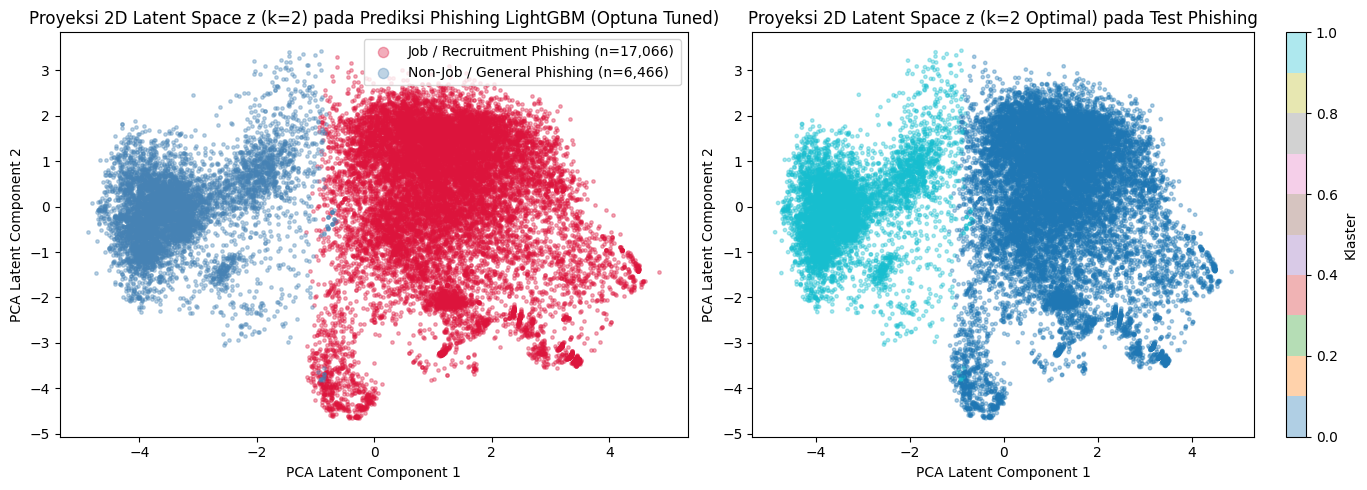

=== UJI UJUNG-KE-UJUNG: 23,532 URL test diprediksi phishing, ditetapkan ke klaster model yang sudah dilatih ===


,n,benar_phishing,salah_tandai_legitimate,jangkar,persen_test,persen_train,persen_FP_dalam_klaster
klaster,,,,,,,
0,17066,16510,556,48,72.52,78.03,3.26
1,6466,6459,7,9,27.48,21.97,0.11


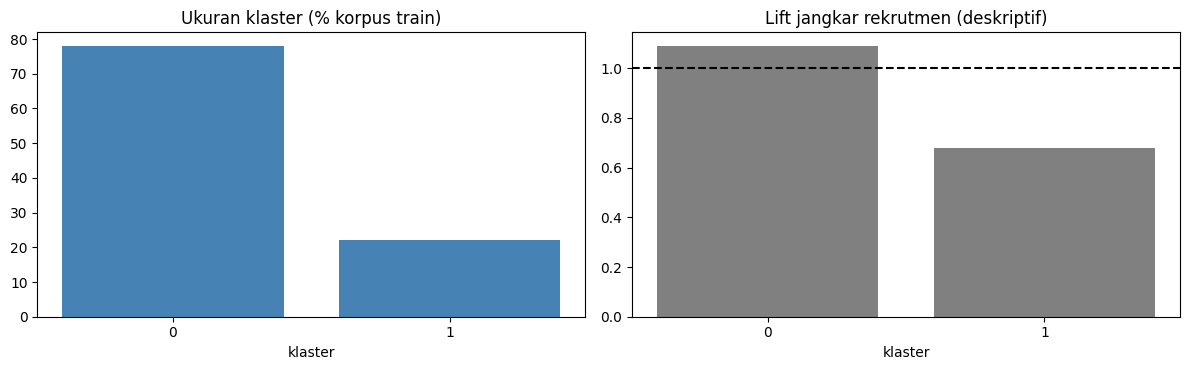

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import PCA
FINAL_SEED = SEEDS[0]

# --- A. PEMETAAN LANGSUNG k = 2 (KLASTER JOB PHISHING VS NON-JOB PHISHING) ---
sc_k2, km_k2 = km_fit(EMB[('hybrid', FINAL_SEED)][0], 2, FINAL_SEED)
lab_tr_k2 = km_k2.labels_
lab_te_k2 = km_k2.predict(sc_k2.transform(EMB[('hybrid', FINAL_SEED)][1]))
at_k2 = anchor_table(lab_tr_k2, anc_tr_loose)
job_cluster_k2 = int(at_k2['lift'].fillna(0).idxmax())
k2_map = {job_cluster_k2: 'Cluster Job / Recruitment Phishing', 1 - job_cluster_k2: 'Cluster Non-Job / General Phishing'}

prof_feats = [f for f in ['urllength', 'domainnamelength', 'subdomaincount', 'pathlength', 'count_slashes', 'count_dashes', 'hyphenindomain', 'httpsflag', 'urlentropy', 'tokencount', 'tldlength'] if f in FEATURES]
k2_prof_tr = phish_df[prof_feats].groupby([k2_map[c] for c in lab_tr_k2]).mean().round(2)
k2_prof_tr['n_train_phish'] = pd.Series([k2_map[c] for c in lab_tr_k2]).value_counts()
k2_prof_tr['n_test_pred_phish'] = pd.Series([k2_map[c] for c in lab_te_k2]).value_counts()
k2_prof_tr['jangkar_gabungan_train'] = pd.Series(anc_tr_loose).groupby([k2_map[c] for c in lab_tr_k2]).sum()
print('=== KLASTERISASI BINER (k = 2): JOB PHISHING VS NON-JOB PHISHING (HYBRID SELF-ATTENTION AE) ===')
display(k2_prof_tr)
k2_prof_tr.to_csv(os.path.join(OUT_DIR, 'tabel_7a_klaster_biner_job_vs_nonjob.csv'))

# Visualisasi Proyeksi 2D Ruang Laten (PCA) pada Hasil Prediksi Phishing Model Terbaik (Test Set)
pca_2d = PCA(n_components=2, random_state=SEED)
Z_te_2d = pca_2d.fit_transform(sc_k2.transform(EMB[('hybrid', FINAL_SEED)][1]))
fig_pca, ax_pca = plt.subplots(1, 2, figsize=(14, 5))
for c_id, c_name, col in [(job_cluster_k2, 'Job / Recruitment Phishing', 'crimson'), (1 - job_cluster_k2, 'Non-Job / General Phishing', 'steelblue')]:
    m_c = lab_te_k2 == c_id
    ax_pca[0].scatter(Z_te_2d[m_c, 0], Z_te_2d[m_c, 1], s=6, alpha=0.35, c=col, label=f'{c_name} (n={m_c.sum():,})')
ax_pca[0].set_title(f'Proyeksi 2D Latent Space z (k=2) pada Prediksi Phishing {BEST_NAME}')
ax_pca[0].set_xlabel('PCA Latent Component 1'); ax_pca[0].set_ylabel('PCA Latent Component 2'); ax_pca[0].legend(markerscale=3)

# --- B. PROFIL MULTI-KLASTER PADA k TERPILIH (K_SEL) ---
lab_final = LABELS_BY_VARIANT['hybrid'][FINAL_SEED]
sc_final, km_final = km_fit(EMB[('hybrid', FINAL_SEED)][0], K_SEL, FINAL_SEED)
assert (km_final.labels_ == lab_final).all()

at = anchor_table(lab_final, anc_tr)
at['kandidat_rekrutmen'] = (at['lift'] >= 3) & (at['jangkar'] >= 5)
prof = phish_df[prof_feats].groupby(lab_final).mean()
top_dom = phish_df.groupby(lab_final)['group'].apply(lambda s: ', '.join(f'{g} ({c / len(s) * 100:.0f}%)' for g, c in s.value_counts().head(4).items()))
cv_tok = CountVectorizer(binary=True, token_pattern=r'\b[a-z]{3,}\b', min_df=30 if not SMOKE_TEST else 5, lowercase=True); Xb = cv_tok.fit_transform(texts_tr); vocab_arr = np.array(cv_tok.get_feature_names_out())
def top_tokens(c, n=8):
    m = lab_final == c; n_in, n_out = np.asarray(Xb[m].sum(0)).ravel(), np.asarray(Xb[~m].sum(0)).ravel()
    lo = np.log((n_in + .5) / (m.sum() + 1)) - np.log((n_out + .5) / ((~m).sum() + 1)); keep = n_in >= 5
    idx = np.argsort(-np.where(keep, lo, -9))[:n]; return ', '.join(vocab_arr[idx])
cluster_profile = pd.concat([at.set_index('klaster'), prof.round(2)], axis=1)
cluster_profile['domain_terbanyak'] = top_dom; cluster_profile['token_khas'] = [top_tokens(c) for c in cluster_profile.index]
print(f'\n=== PROFIL MULTI-KLASTER (hybrid seed {FINAL_SEED}, k = {K_SEL}, n = {len(lab_final):,}) ===')
pd.set_option('display.max_colwidth', 70)
display(cluster_profile.style.format({'persen': '{:.2f}', 'jangkar_persen': '{:.3f}', 'lift': '{:.2f}', 'p_hipergeom': '{:.2e}'}))
cluster_profile.to_csv(os.path.join(OUT_DIR, 'tabel_7_profil_klaster.csv'))
CAND = cluster_profile.index[cluster_profile['kandidat_rekrutmen']].tolist()
TARGET_CLUSTER = int(CAND[0]) if CAND else int(cluster_profile['lift'].fillna(0).idxmax())
print('Kandidat klaster bertema rekrutmen (lift >= 3 & jangkar >= 5):', CAND or 'TIDAK ADA')
print(f'Klaster target untuk analisis XAI Tahap 2: {TARGET_CLUSTER} ' + ('(kandidat)' if CAND else '(lift tertinggi; BUKAN kandidat terkonfirmasi)'))
plat = cluster_profile['domain_terbanyak'].str.extract(r'\((\d+)%\)')[0].astype(float)
print('Dominasi domain tunggal terbesar per klaster (%):', plat.round(0).tolist(), '-> nilai tinggi menandakan klaster mengikuti platform hosting.')

# Plot multi-cluster di panel kanan PCA
Zte = EMB[('hybrid', FINAL_SEED)][1]; lab_te = km_final.predict(sc_final.transform(Zte))
scatter_multi = ax_pca[1].scatter(Z_te_2d[:, 0], Z_te_2d[:, 1], c=lab_te, cmap='tab10', s=6, alpha=0.35)
ax_pca[1].set_title(f'Proyeksi 2D Latent Space z (k={K_SEL} Optimal) pada Test Phishing')
ax_pca[1].set_xlabel('PCA Latent Component 1'); ax_pca[1].set_ylabel('PCA Latent Component 2')
plt.colorbar(scatter_multi, ax=ax_pca[1], label='Klaster')
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'gambar_6a_pca_latent_clusters.png'), dpi=220, bbox_inches='tight'); plt.show()

# ---- uji ujung-ke-ujung ----
e2e = pd.DataFrame({'klaster': lab_te, 'benar_phishing': test_pp_y == 1, 'salah_tandai_legitimate': test_pp_y == 0, 'jangkar': anc_te_pp}).groupby('klaster').agg(
    n=('klaster', 'size'), benar_phishing=('benar_phishing', 'sum'), salah_tandai_legitimate=('salah_tandai_legitimate', 'sum'), jangkar=('jangkar', 'sum'))
e2e['persen_test'] = e2e['n'] / e2e['n'].sum() * 100; e2e['persen_train'] = cluster_profile['persen']; e2e['persen_FP_dalam_klaster'] = e2e['salah_tandai_legitimate'] / e2e['n'] * 100
print(f'=== UJI UJUNG-KE-UJUNG: {len(test_pp):,} URL test diprediksi phishing, ditetapkan ke klaster model yang sudah dilatih ===')
display(e2e.style.format({'persen_test': '{:.2f}', 'persen_train': '{:.2f}', 'persen_FP_dalam_klaster': '{:.2f}'}))
e2e.to_csv(os.path.join(OUT_DIR, 'tabel_8_uji_ujung_ke_ujung.csv'))
joblib.dump(dict(scaler=sc_final, kmeans=km_final, k=K_SEL, scaler_k2=sc_k2, kmeans_k2=km_k2, k2_map=k2_map), os.path.join(OUT_DIR, 'stage2_cluster_final.joblib'))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(cluster_profile.index.astype(str), cluster_profile['persen'], color='steelblue'); ax[0].set_title('Ukuran klaster (% korpus train)'); ax[0].set_xlabel('klaster')
ax[1].bar(cluster_profile.index.astype(str), cluster_profile['lift'].fillna(0), color=['crimson' if c in CAND else 'gray' for c in cluster_profile.index]); ax[1].axhline(1, ls='--', c='k'); ax[1].set_title('Lift jangkar rekrutmen (deskriptif)'); ax[1].set_xlabel('klaster')
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'gambar_6_klaster.png'), dpi=220, bbox_inches='tight'); plt.show()

---
# TAHAP 7: Validasi Klaster

Tanpa label, klaim "klaster ini adalah *job phishing*" hanya dapat didukung oleh **label manual independen**. Sel berikut menyiapkan sampel audit; anotasi dilakukan **di luar notebook**, lalu sel analisis dijalankan lagi.

## 7.1 Desain sampel audit
Sampel acak murni hanya memuat sekitar 60 URL berjangkar per 40 ribu sehingga tidak informatif. Sampel dibuat **berstrata**:
* **jangkar:** URL berkata kunci rekrutmen (maks. 30% sampel);
* **tetangga:** 3 tetangga terdekat (kosinus pada ruang laten) dari tiap URL jangkar yang bukan jangkar (maks. 30%), untuk menguji apakah ruang laten menemukan URL bertema serupa **tanpa kata kunci**;
* **acak per klaster:** sisanya dibagi rata ke setiap klaster.

Berkas untuk anotator **tidak memuat strata maupun nomor klaster** (menghindari bias anotator). Kunci disimpan terpisah.

## 7.2 Protokol anotasi (dua anotator independen)
Isi `label_annotator1` dan `label_annotator2` dengan salah satu: **`JOB`** (URL jelas bertema ketenagakerjaan/rekrutmen: lowongan, karier, perekrut, resume/CV, lamaran, atau peniruan platform kerja), **`NONJOB`**, atau **`UNSURE`**. Anotator menilai dari string URL **tanpa membuka situs** (situs *phishing* berbahaya). Simpan sebagai `audit_sample_annotated.csv` di folder keluaran.

## 7.3 Metrik
* ***Cohen's kappa*** antar-anotator: $\kappa=\frac{p_o-p_e}{1-p_e}$ (pada baris yang keduanya berlabel `JOB`/`NONJOB`); label konsensus = baris yang disepakati.
* **Purity** $=\frac1N\sum_c\max_j|c\cap j|$, **ARI** dan **NMI** terhadap label konsensus, untuk setiap varian (hybrid, tok, feat, pembanding).
* **Precision** dan **recall** klaster `JOB` terbaik (klaster dengan jumlah `JOB` terbanyak), dengan **interval Wilson 95%**: $\frac{\hat p+\frac{z^2}{2n}\pm z\sqrt{\frac{\hat p(1-\hat p)}{n}+\frac{z^2}{4n^2}}}{1+\frac{z^2}{n}}$.
* **Peringatan:** karena sampel berstrata (bukan acak), precision/recall **bukan** estimasi prevalensi pada populasi; tulis sebagai kinerja pada sampel audit.

In [ ]:
# ===================== SAMPEL AUDIT BERSTRATA =====================
rng = np.random.RandomState(SEED + 7)
Zn = SPACES['hybrid'][FINAL_SEED]; Zn = Zn / np.linalg.norm(Zn, axis=1, keepdims=True).clip(min=1e-9)
anc_idx = np.where(anc_tr)[0]
n_anc = min(len(anc_idx), int(0.3 * AUDIT_N)); n_nei = int(0.3 * AUDIT_N)
pick_anc = rng.choice(anc_idx, n_anc, replace=False) if len(anc_idx) else np.array([], dtype=int)

neigh = set()
if len(anc_idx):
    sims = torch.as_tensor(Zn[anc_idx]) @ torch.as_tensor(Zn).T                      # (A, N) kosinus
    for r_i, a_i in enumerate(anc_idx):
        sims[r_i, a_i] = -2
    sims[:, torch.as_tensor(anc_tr)] = -2                                           # hanya tetangga non-jangkar
    top3 = torch.topk(sims, 3, dim=1).indices.numpy(); neigh = set(top3.ravel().tolist())
neigh = sorted(neigh - set(pick_anc.tolist())); pick_nei = rng.choice(neigh, min(len(neigh), n_nei), replace=False) if neigh else np.array([], dtype=int)

chosen = set(pick_anc.tolist()) | set(pick_nei.tolist()); per_c = max((AUDIT_N - len(chosen)) // K_SEL, 1); pick_rand = []
for c in range(K_SEL):
    pool = [i for i in np.where(lab_final == c)[0] if i not in chosen]
    pick_rand += list(rng.choice(pool, min(per_c, len(pool)), replace=False)) if pool else []
rows = [(i, 'jangkar') for i in pick_anc] + [(i, 'tetangga_laten') for i in pick_nei] + [(i, 'acak_per_klaster') for i in pick_rand]
audit = pd.DataFrame(rows, columns=['idx', 'stratum']).drop_duplicates('idx').sample(frac=1, random_state=SEED).reset_index(drop=True)
audit['id'] = np.arange(1, len(audit) + 1); audit['URL'] = phish_df.loc[audit['idx'], 'URL'].to_numpy(); audit['klaster_hybrid'] = lab_final[audit['idx']]
audit[['id', 'URL']].assign(label_annotator1='', label_annotator2='').to_csv(os.path.join(OUT_DIR, 'audit_sample_for_annotation.csv'), index=False)
audit[['id', 'URL', 'stratum', 'klaster_hybrid']].to_csv(os.path.join(OUT_DIR, 'audit_sample_key.csv'), index=False)
print(f'Sampel audit: {len(audit)} URL | per strata: {audit["stratum"].value_counts().to_dict()}')
print('Berkas untuk anotator :', os.path.join(OUT_DIR, 'audit_sample_for_annotation.csv'))
print('Setelah dilabeli, simpan sebagai:', os.path.join(OUT_DIR, 'audit_sample_annotated.csv'), '(kolom: id, URL, label_annotator1, label_annotator2)')
display(audit[['id', 'URL', 'stratum', 'klaster_hybrid']].head(8))

Sampel audit: 450 URL | per strata: {'acak_per_klaster': 248, 'tetangga_laten': 135, 'jangkar': 67}
Berkas untuk anotator : /content/drive/MyDrive/ICDSOS/hasil_pipeline_v2/audit_sample_for_annotation.csv
Setelah dilabeli, simpan sebagai: /content/drive/MyDrive/ICDSOS/hasil_pipeline_v2/audit_sample_annotated.csv (kolom: id, URL, label_annotator1, label_annotator2)


,id,URL,stratum,klaster_hybrid
0,1,https://q-r.to/bgaOV3,acak_per_klaster,1
1,2,https://l.ead.me/bgbZmp,acak_per_klaster,1
2,3,https://come.ac/7OdDQ,tetangga_laten,1
3,4,https://www.cakeresume.com/s--YhMRr_UcaqV8x7fKRttnrw--/terri-hailey,jangkar,0
4,5,https://bit.ly/3APHBSd,acak_per_klaster,1
5,6,https://app-promocopa2026.myshopify.com/products/micro-ondas-elect...,tetangga_laten,0
6,7,http://steamcommunitylog.chez.com/index.php,acak_per_klaster,0
7,8,https://forms.gle/SGwTf7t6av9ZRANa6,acak_per_klaster,1


In [ ]:
# ===================== ANALISIS SETELAH ANOTASI (jalankan ulang sel ini setelah berkas anotasi tersedia) =====================
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; den = 1 + z * z / n; c = (p + z * z / (2 * n)) / den; h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(c - h, 0), min(c + h, 1))

ANN_PATH = os.path.join(OUT_DIR, 'audit_sample_annotated.csv')
manual_results = None
if not os.path.exists(ANN_PATH):
    print('Berkas anotasi belum ada. Lewati sel ini sekarang; setelah dua anotator selesai, simpan', ANN_PATH, 'lalu jalankan ulang sel ini saja.')
else:
    ann = pd.read_csv(ANN_PATH); key = pd.read_csv(os.path.join(OUT_DIR, 'audit_sample_key.csv')); asg = pd.read_csv(os.path.join(OUT_DIR, 'cluster_assignments_train_phish.csv.gz'))
    for c in ['label_annotator1', 'label_annotator2']: ann[c] = ann[c].astype(str).str.strip().str.upper()
    both = ann[ann['label_annotator1'].isin(['JOB', 'NONJOB']) & ann['label_annotator2'].isin(['JOB', 'NONJOB'])]
    kappa = cohen_kappa_score(both['label_annotator1'], both['label_annotator2'])
    cons = both[both['label_annotator1'] == both['label_annotator2']].merge(key[['id', 'stratum']], on='id', how='left').merge(asg, on='URL', how='left')
    y_job = (cons['label_annotator1'] == 'JOB').astype(int).to_numpy()
    print(f'Baris berlabel lengkap: {len(both)} | kappa = {kappa:.3f} | konsensus: {len(cons)} (JOB = {y_job.sum()}, NONJOB = {(1 - y_job).sum()})')
    print('Distribusi label konsensus per strata:'); display(pd.crosstab(cons['stratum'], cons['label_annotator1']))
    rows = []
    for v in [c for c in asg.columns if c != 'URL']:
        lab = cons[v].to_numpy(); ct = pd.crosstab(lab, y_job)
        purity = ct.max(axis=1).sum() / ct.values.sum()
        best_c = ct[1].idxmax() if 1 in ct.columns else None
        tp = int(ct.loc[best_c, 1]) if best_c is not None else 0; n_c = int(ct.loc[best_c].sum()) if best_c is not None else 0; tot_job = int(y_job.sum())
        p_lo, p_hi = wilson(tp, n_c); r_lo, r_hi = wilson(tp, tot_job)
        rows.append(dict(Varian=v, Purity=purity, ARI=adjusted_rand_score(y_job, lab), NMI=normalized_mutual_info_score(y_job, lab), klaster_JOB_terbaik=best_c,
                         Precision=tp / max(n_c, 1), Precision_CI=f'[{p_lo:.2f}, {p_hi:.2f}]', Recall=tp / max(tot_job, 1), Recall_CI=f'[{r_lo:.2f}, {r_hi:.2f}]', n_klaster=n_c))
    manual_results = pd.DataFrame(rows); display(manual_results.style.format({'Purity': '{:.3f}', 'ARI': '{:.3f}', 'NMI': '{:.3f}', 'Precision': '{:.3f}', 'Recall': '{:.3f}'}))
    manual_results.to_csv(os.path.join(OUT_DIR, 'tabel_9_validasi_manual.csv'), index=False)
    print('Ingat: sampel berstrata -> metrik ini adalah kinerja pada sampel audit, bukan estimasi prevalensi populasi. Jika TF-IDF/fitur mentah sama baik atau lebih baik, laporkan apa adanya.')

Berkas anotasi belum ada. Lewati sel ini sekarang; setelah dua anotator selesai, simpan /content/drive/MyDrive/ICDSOS/hasil_pipeline_v2/audit_sample_annotated.csv lalu jalankan ulang sel ini saja.


---
# TAHAP 8: XAI Tahap 2 (Attention Rollout, Token Occlusion, Profil Centroid)

Dua teknik komplementer dipakai karena bobot atensi mentah **bukan** penjelasan otomatis:

* ***Attention rollout*** (Abnar & Zuidema): pada tiap layer, $\hat A_l=\tfrac12\bar A_l+\tfrac12 I$ ($\bar A_l$ = rata-rata antar-*head*), lalu $R=\hat A_L\hat A_{L-1}\cdots\hat A_1$. Kepentingan token $j$ adalah $R_{\text{CLS},j}$ yang dinormalisasi.
* ***Token occlusion***: setiap token diganti `[MASK]` satu per satu; kepentingan $=1-\cos(\mathbf z,\mathbf z_{\setminus j})$, yaitu seberapa jauh posisi URL di ruang laten bergeser.
* **Profil centroid**: $(\bar x_{c,f}-\bar x_f)/s_f$ per fitur dan klaster.

Token dikumpulkan per string dan hanya token alfabetis yang muncul $\ge 5$ kali yang dilaporkan. Penjelasan ini menggambarkan apa yang dipakai model untuk menempatkan URL di ruang laten, **bukan** bukti bahwa token tersebut menandakan *job phishing*.

=== TOKEN PENTING: klaster target 0 (250 URL, termasuk semua jangkar di klaster tersebut) ===


,n,self_attn_mean,rollout_mean,occlusion_mean
token,,,,
bradesco,6,0.2808,0.1708,0.0241
pro,5,0.1298,0.1305,0.0164
allegrolokalnie,10,0.2632,0.2192,0.0148
shop,5,0.3985,0.2076,0.0137
io,11,0.1084,0.1274,0.0137
firebaseapp,11,0.3252,0.1287,0.0115
weebly,21,0.1836,0.1769,0.0097
web,12,0.1871,0.0958,0.0097
app,30,0.1149,0.1847,0.0077


=== TOKEN PENTING: sampel acak seluruh korpus (pembanding) ===


,n,self_attn_mean,rollout_mean,occlusion_mean
token,,,,
top,8,0.4217,0.2647,0.0279
pro,7,0.1646,0.1382,0.0172
bradesco,6,0.2565,0.1568,0.0138
allegrolokalnie,10,0.1885,0.1686,0.0129
cc,5,0.1752,0.0945,0.0125
weebly,23,0.1763,0.1617,0.0119
net,6,0.1313,0.1510,0.0114
app,20,0.1249,0.1910,0.0100
link,7,0.1785,0.1043,0.0099



Contoh URL (3 token teratas menurut occlusion):
  http://allegrolokalnie.id-38247ns4.click -> ['allegrolokalnie', 'click', 'id']
  https://geicorecruiters.us-mia-1.linodeobjects.com/Linkedinpage.html -> ['us', 'com', 'ia']
  https://www.cakeresume.com/s--qLDzocKp83eiJhM5mvFyQA--/at-t-0f3181 -> ['com', 'at', 'cakeresume']
  https://partners.costumer.balearyc.com/files/?45NVN=45VBV -> ['com', 'co', 'files']
  https://brief-qz-wraith-3e76.s3.ca-central-1.amazonaws.com/dVusuWlgwz8?email=red -> ['com', 'amazonaws', 'com']
  https://storage.ghost.io/c/f5/c8/f5c8d86e-a923-41f2-b598-72858788c697/content/fi -> ['io', 'ghost', 'storage']


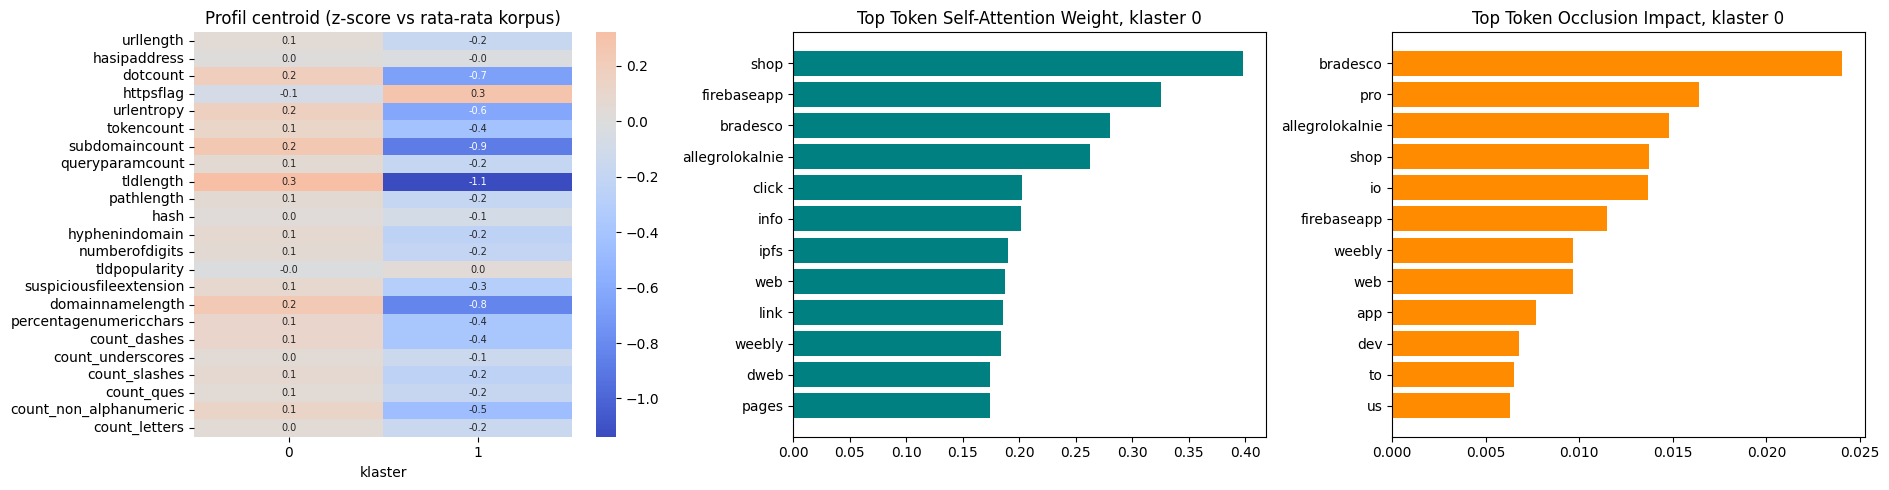

Waktu berjalan: 3.8 menit


In [ ]:
# ===================== XAI TAHAP 2 (SELF-ATTENTION WEIGHTS, ROLLOUT, & OCCLUSION) =====================
model_x = URLAE(V, feats_tr.shape[1], **VARIANTS['hybrid']).to(DEVICE)
model_x.load_state_dict(torch.load(os.path.join(OUT_DIR, f'ae_hybrid_s{FINAL_SEED}.pt'), map_location=DEVICE)); model_x.eval()

@torch.no_grad()
def rollout_and_pool_attn(ids_t, feats_t):
    _, _, attns = model_x.encode(ids_t, feats_t, return_attn=True); B, L = ids_t.shape
    pool_alpha = model_x.last_pool_alpha.float().cpu().numpy()
    I = torch.eye(L, device=ids_t.device); R = I.expand(B, L, L).clone()
    for A in attns: R = (0.5 * A.float().mean(1) + 0.5 * I) @ R
    imp = R[:, 0, :].clone(); imp[:, 0] = 0; imp[ids_t == PAD_ID] = 0
    ro = (imp / imp.sum(1, keepdim=True).clamp(min=1e-9)).cpu().numpy()
    return ro, pool_alpha

@torch.no_grad()
def occlusion(ids_t, feats_t):
    z0 = model_x.encode(ids_t, feats_t)[0]; B, L = ids_t.shape; out = torch.zeros(B, L, device=ids_t.device)
    for j in range(1, L):
        valid = ids_t[:, j] != PAD_ID
        if not valid.any(): continue
        x = ids_t.clone(); x[:, j] = MASK_ID
        out[:, j] = (1 - F.cosine_similarity(z0, model_x.encode(x, feats_t)[0], dim=-1)) * valid
    return out.cpu().numpy()

def token_importance(idx_list):
    ids_t = torch.as_tensor(ids_tr[idx_list], device=DEVICE); f_t = torch.as_tensor(feats_tr[idx_list], device=DEVICE)
    ro, pa = rollout_and_pool_attn(ids_t, f_t)
    oc = occlusion(ids_t, f_t); recs = []
    for r in range(len(idx_list)):
        for j in range(1, MAX_LEN):
            t = ID2TOK[int(ids_tr[idx_list[r], j])]
            if ids_tr[idx_list[r], j] != PAD_ID and re.fullmatch(r'[a-z]{2,}', t):
                recs.append((t, pa[r, j], ro[r, j], oc[r, j]))
    return ro, oc, pd.DataFrame(recs, columns=['token', 'self_attn_weight', 'rollout', 'occlusion'])

rs2 = np.random.RandomState(SEED + 11)
pool_t = np.where(lab_final == TARGET_CLUSTER)[0]; anc_in_t = [i for i in pool_t if anc_tr[i]]
sel_t = np.array((anc_in_t + list(rs2.choice(pool_t, min(OCC_URLS, len(pool_t)), replace=False)))[:max(OCC_URLS, len(anc_in_t))]); sel_t = np.unique(sel_t)
sel_all = rs2.choice(len(ids_tr), min(OCC_URLS, len(ids_tr)), replace=False)
min_n = 5 if not SMOKE_TEST else 2
def agg(df):
    g = df.groupby('token').agg(n=('token', 'size'), self_attn_mean=('self_attn_weight', 'mean'), rollout_mean=('rollout', 'mean'), occlusion_mean=('occlusion', 'mean'))
    return g[g['n'] >= min_n].sort_values('occlusion_mean', ascending=False)
ro_t, oc_t, df_t = token_importance(sel_t); _, _, df_a = token_importance(sel_all)
tok_target, tok_all = agg(df_t), agg(df_a)
print(f'=== TOKEN PENTING: klaster target {TARGET_CLUSTER} ({len(sel_t)} URL, termasuk semua jangkar di klaster tersebut) ===')
display(tok_target.head(15).style.format({'self_attn_mean': '{:.4f}', 'rollout_mean': '{:.4f}', 'occlusion_mean': '{:.4f}'}))
print('=== TOKEN PENTING: sampel acak seluruh korpus (pembanding) ==='); display(tok_all.head(10).style.format({'self_attn_mean': '{:.4f}', 'rollout_mean': '{:.4f}', 'occlusion_mean': '{:.4f}'}))
tok_target.to_csv(os.path.join(OUT_DIR, 'tabel_10_token_klaster_target.csv')); tok_all.to_csv(os.path.join(OUT_DIR, 'tabel_10b_token_acak.csv'))

print('\nContoh URL (3 token teratas menurut occlusion):')
for r in range(min(6, len(sel_t))):
    i = sel_t[r]; toks = [(ID2TOK[int(ids_tr[i, j])], oc_t[r, j]) for j in range(1, MAX_LEN) if ids_tr[i, j] != PAD_ID and re.fullmatch(r'[a-z]{2,}', ID2TOK[int(ids_tr[i, j])])]
    print(' ', phish_df.loc[i, 'URL'][:80], '->', [t for t, _ in sorted(toks, key=lambda x: -x[1])[:3]])

zc = (phish_df[FEATURES].groupby(lab_final).mean() - phish_df[FEATURES].mean()) / phish_df[FEATURES].std().replace(0, np.nan)
fig, ax = plt.subplots(1, 3, figsize=(19, 5))
sns.heatmap(zc.T, cmap='coolwarm', center=0, annot=True, fmt='.1f', annot_kws={'size': 7}, ax=ax[0]); ax[0].set_title('Profil centroid (z-score vs rata-rata korpus)'); ax[0].set_xlabel('klaster')
top_plot_attn = tok_target.sort_values('self_attn_mean', ascending=False).head(12)[::-1]
ax[1].barh(top_plot_attn.index, top_plot_attn['self_attn_mean'], color='teal'); ax[1].set_title(f'Top Token Self-Attention Weight, klaster {TARGET_CLUSTER}')
top_plot = tok_target.head(12)[::-1]; ax[2].barh(top_plot.index, top_plot['occlusion_mean'], color='darkorange'); ax[2].set_title(f'Top Token Occlusion Impact, klaster {TARGET_CLUSTER}')
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'gambar_7_xai_stage2.png'), dpi=220, bbox_inches='tight'); plt.show()
print(f'Waktu berjalan: {elapsed_min():.1f} menit')

---
# Ringkasan Otomatis, Keterbatasan, dan Cara Menulis Kesimpulan

Sel berikut mencetak ringkasan **dari hasil eksekusi aktual** dan menyimpannya sebagai `ringkasan_hasil.md`. Semua angka di paper harus diambil dari sini atau dari tabel CSV di folder keluaran, bukan dari draf lama.

In [ ]:
L = []
def P(s=''): print(s); L.append(s)
P('=== RINGKASAN HASIL EKSPERIMEN ===' + ('  [SMOKE_TEST: BUKAN HASIL PAPER]' if SMOKE_TEST else ''))
P(f'Data: train {len(train_df):,} (phishing {int(y_train.sum()):,}), test {len(test_df):,} (phishing {int(y_test.sum()):,}); grup train {train_df["group"].nunique():,}; fitur aktif {len(FEATURES)}.')
P(f'Test dengan domain sudah ada di train: {test_seen_mask.mean():.1%}; URL train beririsan test yang dibuang: {len(overlap):,}.')
P(f'[TAHAP 1 PENELITIAN] Model terpilih (CV grup): {BEST_NAME}; mean CV F1 = {cv_table.loc[0, "CV_F1_Mean"]:.4f} +- {cv_table.loc[0, "CV_F1_Std"]:.4f}; ambang OOF = {THR:.2f}.')
m_all = test_table[(test_table['Ambang'] == f'tau OOF = {THR:.2f}') & (test_table['Subset test'] == 'Seluruh test')].iloc[0]
P(f'Test (seluruh): Acc {m_all["Accuracy"]:.4f} | P {m_all["Precision"]:.4f} | R {m_all["Recall"]:.4f} | F1 {m_all["F1"]:.4f} (CI bootstrap [{f1_ci[0]:.4f}, {f1_ci[1]:.4f}]) | ROC-AUC {m_all["ROC_AUC"]:.4f} | PR-AUC {m_all["PR_AUC"]:.4f}')
m_new = test_table[(test_table['Ambang'] == f'tau OOF = {THR:.2f}') & (test_table['Subset test'] == 'Domain BELUM pernah dilihat')]
if len(m_new): P(f'Test (domain belum pernah dilihat, n={int(m_new.iloc[0]["n"]):,}): F1 {m_new.iloc[0]["F1"]:.4f} | ROC-AUC {m_new.iloc[0]["ROC_AUC"]:.4f} | PR-AUC {m_new.iloc[0]["PR_AUC"]:.4f}')
P('Ablasi fitur path (ambang 0,50):'); P(ablation_path.round(4).to_string(index=False))
if stump_rows: P('Diagnostik: ' + '; '.join(f'{r["Model"]} F1={r["F1_test"]:.4f}' for r in stump_rows))
P('Top 5 fitur (Mean |SHAP|): ' + '; '.join(f'{r.Feature} ({r.Mean_Abs_SHAP:.3f}; gain {r["Total_Gain_Ratio_%"]:.1f}%; perm {r.Permutation_F1_Drop:.4f})' for _, r in fi_summary.head(5).iterrows()))
P(f'[TAHAP 2 PENELITIAN - EKSPLORATIF] Korpus latih {len(phish_df):,} URL phishing; jangkar strict {int(anc_tr.sum())} ({anc_tr.mean():.2%}); k terpilih {K_SEL}; model final hybrid seed {FINAL_SEED}.')
P('Ablasi klaster:'); P(ablation_clusters.round(4).to_string(index=False))
P(f'Kandidat klaster rekrutmen (lift>=3 & jangkar>=5): {CAND or "tidak ada"}; ukuran klaster terbesar {cluster_profile["persen"].max():.1f}%.')
P(f'Uji ujung-ke-ujung: {len(test_pp):,} URL test diprediksi phishing, {(test_pp_y == 0).sum():,} di antaranya legitimate (error propagation).')
if manual_results is not None: P('Validasi manual:'); P(manual_results.round(3).to_string(index=False))
else: P('Validasi manual: BELUM dilakukan (lihat Tahap 7). Tanpa ini, klaim tentang job phishing hanya boleh berupa hipotesis.')
P(f'Total waktu eksekusi sel: {elapsed_min():.1f} menit | perangkat {DEVICE}.')
open(os.path.join(OUT_DIR, 'ringkasan_hasil.md'), 'w', encoding='utf-8').write('\n'.join(L))
print('\nSemua keluaran tersimpan di:', OUT_DIR)

=== RINGKASAN HASIL EKSPERIMEN ===
Data: train 78,236 (phishing 38,305), test 38,128 (phishing 23,476); grup train 48,560; fitur aktif 23.
Test dengan domain sudah ada di train: 49.8%; URL train beririsan test yang dibuang: 716.
[TAHAP 1 PENELITIAN] Model terpilih (CV grup): LightGBM (Optuna Tuned); mean CV F1 = 0.9783 +- 0.0093; ambang OOF = 0.49.
Test (seluruh): Acc 0.9719 | P 0.9761 | R 0.9784 | F1 0.9772 (CI bootstrap [0.9758, 0.9787]) | ROC-AUC 0.9950 | PR-AUC 0.9971
Test (domain belum pernah dilihat, n=19,143): F1 0.8948 | ROC-AUC 0.9794 | PR-AUC 0.9572
Ablasi fitur path (ambang 0,50):
                                                                                    Skenario fitur                 Subset test     F1  ROC_AUC  PR_AUC
                                                                                       Semua fitur                Seluruh test 0.9772   0.9950  0.9971
                                                                                       Semua fitur 

### Keterbatasan yang wajib ditulis di paper
1. **Tidak ada *ground truth* job phishing.** Tahap 2 bersifat eksploratif; klaim dibatasi pada ada/tidaknya struktur laten bertema rekrutmen dan kejelasannya, bukan pada "akurasi deteksi".
2. **Sinyal rekrutmen sangat jarang** (jangkar kurang dari 1% URL *phishing*) dan sebagian jangkar bukan penipuan lowongan. Klaster berukuran besar kemungkinan mengikuti platform hosting.
3. **Validasi manual berukuran kecil** dan berstrata: interval kepercayaan lebar, dan metrik bukan estimasi prevalensi.
4. **Dominasi struktur path/platform** pada Tahap 1 (lihat audit, stump, dan ablasi): skor tinggi tidak otomatis berarti model memahami anatomi domain *phishing*.
5. **Dataset gabungan**: sumber *phishing* dan *legitimate* berbeda dapat menimbulkan bias sumber (mis. *legitimate* hampir semuanya halaman utama).
6. **Satu pembagian train/test**; tidak ada uji lintas waktu atau lintas sumber. Interval bootstrap pada level baris terlalu sempit untuk data berkelompok.
7. **Uji statistik 5 fold bersifat eksploratif**; $p>0{,}05$ bukan bukti kesetaraan algoritma.
8. XAI (SHAP, atensi, occlusion) menjelaskan model, bukan kausalitas.

### Kerangka kesimpulan (isi dengan angka dari ringkasan otomatis)
* **Tahap 1:** "Pada dataset gabungan berukuran [n], [model terpilih] mencapai F1 [x] (CV grup) dan [y] pada test, dengan [z] pada subset domain baru. Skor sangat dipengaruhi [fitur path/platform] (ablasi: [angka])."
* **Tahap 2:** "Eksplorasi pada [m] URL *phishing* menghasilkan [k] klaster yang stabil (ARI [a]). [Ada/Tidak ada] klaster dengan pengayaan kata kunci rekrutmen (lift [l]). Validasi manual pada [N] URL menunjukkan [purity/precision dengan CI]. Dibandingkan pembanding TF-IDF, model [lebih baik/setara/lebih buruk]."
* Gunakan kata **"mengeksplorasi"** dan **"mengidentifikasi kandidat klaster bertema rekrutmen"**, bukan "mendeteksi job phishing".